# Salary Predictor

You have been offered a job! But how much should you get paid?

This project aims to predict base salaries by using machine learning regression models trained on over 62,000 crowd-sourced salary records, which were obtained from Levels.fyi. 

In [601]:
import os
import socket
import warnings
warnings.filterwarnings('ignore')
if socket.gethostname() == "cs-nexus":
    os.chdir(os.path.expanduser("~"))
    notebooks_dir = "ca1"
    datasets_dir = "/home/shared/CS3515_Datasets"
elif "google.colab" in str(get_ipython()):
    from google.colab import drive
    drive.mount("/content/drive")
    notebooks_dir = "/content/drive/MyDrive/CS3515_Notebooks"
    datasets_dir = "/content/drive/MyDrive/CS3515_Datasets"
else:
    notebooks_dir = "."
    datasets_dir = "../CS3515_Datasets"

In [602]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV, RandomizedSearchCV
from sklearn.base import BaseEstimator, TransformerMixin, clone
from pandas.plotting import scatter_matrix
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler, RobustScaler, StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingRegressor

In [603]:
rng = np.random.RandomState(2)

# Understand the business problem

We want to predict the base salary we should expect to receive for a job offer using crowd-sourced salary data. We can do this through training a regression model to predict base salaries.

# Performance measures

- MAE: Will be useful as it will be less sensitive to the large errors that may be present in the likely noisy crowd-sourced dataset.
- RMSE: Will be useful since it penalises larger errors, but have to be wary when using it as it may be strongly influenced by the likely noisy crowd-sourced dataset.
- DummyRegressor: Have a baseline to compare our results against.

Most likely use RMSE as our primary performance measure since it is suitable for salary data. This is as it penalises large errors more, however we will need to ensure we do a good job of cleaning up our dataset since it is sensitive to more noisy data.

# Acquire our dataset

In [604]:
df = pd.read_csv(os.path.join(datasets_dir, "salaries.csv"))

# Take a cheeky look

In [605]:
df.head()

,timestamp,company,level,title,totalyearlycompensation,location,yearsofexperience,yearsatcompany,tag,basesalary,stockgrantvalue,bonus,gender,otherdetails,cityid,dmaid,rowNumber
0,6/7/2017 11:33:27,Oracle,L3,Product Manager,186,"Redwood City, CA",1,1,NaN,160,17,9,NaN,NaN,7392,807.0,1
1,6/10/2017 17:11:29,eBay,SE 2,Software Engineer,0,"San Francisco, CA",3,4,NaN,0,0,0,NaN,NaN,7419,807.0,2
2,6/11/2017 14:53:57,Amazon,L7,Product Manager,126,"Seattle, WA",10,0,NaN,126,0,0,NaN,NaN,11527,819.0,3
3,6/14/2017 21:22:25,Microsoft,64,Software Engineering Manager,171348,"Redmond, WA",13,13,NaN,92799,55371,23178,NaN,NaN,11521,819.0,5
4,6/16/2017 10:44:01,Amazon,L5,Software Engineer,214175,"Vancouver, BC, Canada",13,1,NaN,156335,0,57840,NaN,NaN,1320,0.0,6


- Note: Some missing values for certain features.
- Note: totalyearlycompensation, basesalary, stockgrantvalue, and bonus have quite a large range of values and are potentially using inconsistent units, or else may be errors.
- Note: The target is basesalary.


In [606]:
df.shape

(62642, 17)

In [607]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62642 entries, 0 to 62641
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                62642 non-null  str    
 1   company                  62637 non-null  str    
 2   level                    62523 non-null  str    
 3   title                    62642 non-null  str    
 4   totalyearlycompensation  62642 non-null  int64  
 5   location                 62642 non-null  str    
 6   yearsofexperience        62642 non-null  int64  
 7   yearsatcompany           62642 non-null  int64  
 8   tag                      61772 non-null  str    
 9   basesalary               62642 non-null  int64  
 10  stockgrantvalue          62642 non-null  int64  
 11  bonus                    62642 non-null  int64  
 12  gender                   43102 non-null  str    
 13  otherdetails             40139 non-null  str    
 14  cityid                   62642 no

- Note: Some features contain missing values (company, level, tag, gender, otherdetails, dmaid)

In [608]:
df.describe(include="all")

,timestamp,company,level,title,totalyearlycompensation,location,yearsofexperience,yearsatcompany,tag,basesalary,stockgrantvalue,bonus,gender,otherdetails,cityid,dmaid,rowNumber
count,62642,62637,62523,62642,6.264200e+04,62642,62642.000000,62642.000000,61772,6.264200e+04,6.264200e+04,62642.000000,43102,40139,62642.000000,62640.000000,62642.000000
unique,62561,1869,3070,15,NaN,1050,NaN,NaN,3270,NaN,NaN,NaN,4,40132,NaN,NaN,NaN
top,1/10/2019 21:44:02,Amazon,L4,Software Engineer,NaN,"Seattle, WA",NaN,NaN,Full Stack,NaN,NaN,NaN,Male,whuott,NaN,NaN,NaN
freq,3,8054,5008,41231,NaN,8701,NaN,NaN,11382,NaN,NaN,NaN,35702,2,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,3.175327e+03,NaN,7.191054,2.700616,NaN,1.798145e+03,1.134865e+03,242.317199,NaN,NaN,9856.201989,616.097222,41694.723732
std,NaN,NaN,NaN,NaN,3.877877e+04,NaN,6.437148,3.524030,NaN,1.927194e+04,2.520611e+04,3709.187697,NaN,NaN,6679.104563,289.843390,24488.865879
min,NaN,NaN,NaN,NaN,0.000000e+00,NaN,0.000000,0.000000,NaN,0.000000e+00,0.000000e+00,0.000000,NaN,NaN,0.000000,0.000000,1.000000
25%,NaN,NaN,NaN,NaN,1.160000e+02,NaN,3.000000,0.000000,NaN,8.800000e+01,0.000000e+00,1.000000,NaN,NaN,7369.000000,506.000000,20069.250000
50%,NaN,NaN,NaN,NaN,1.830000e+02,NaN,6.000000,1.000000,NaN,1.310000e+02,2.300000e+01,13.000000,NaN,NaN,7839.000000,807.000000,42019.000000
75%,NaN,NaN,NaN,NaN,2.690000e+02,NaN,10.000000,4.000000,NaN,1.810000e+02,6.400000e+01,27.000000,NaN,NaN,11521.000000,807.000000,63021.750000


- Note: Max yearsofexperience and max yearsatcompany are both 90 which seem to be errors.
- Note: Max rowNumber is 83875 which appears to be an error.
- Note: For totalyearlycompensation, basesalary, stockgrantvalue, and bonus the mean and median differ largely. The mean is quite larger than the median, indicating it is being brought upwards by large values. This is likely related to the inconsistent units, or errors that we noted earlier.

# Clean up dataset

Since we have values of yearsofexperience being 90 and yearsatcompany being 90, investigate rows with large values of these features (larger than 50).

In [609]:
df[(df["yearsofexperience"] >= 50) | (df["yearsatcompany"] >= 50)][["yearsofexperience", "yearsatcompany"]]

,yearsofexperience,yearsatcompany
502,57,7
7785,50,8
8388,57,12
21345,50,2
30318,53,2
32542,51,2
33090,58,2
33950,51,8
40752,57,20
41218,53,30


Remove this row as it appears to be an error.

In [610]:
df = df[(df["yearsofexperience"] != 90) & (df["yearsatcompany"] != 90)]

I want to now try and sort problem regarding totalyearlycompensation, basesalary, stockgrantvalue, and bonus. I check first to see if it is a company-by-company unit inconsistency problem. I will select the 25 companies with the highest base salaries and sort it in a descending order.

In [611]:
company_salaries = (df.groupby("company")["basesalary"].agg(["median", "max"]).sort_values("max", ascending=False)).head(25)

company_salaries

,median,max
company,,
Squarespace,177.0,2057772
Microsoft,135.0,1098310
Netflix,456.0,560740
Airbnb,171.0,368829
linkedin,158.5,357078
Facebook,163.0,355372
EY,107.0,351239
salesforce,190.0,334818
Google,144.0,314478


From this I can see that it is not solely a company-by-company monetary inconsistency problem as it appears the same company uses different monetary scales. We can tell as most medians are in the hundreds, but most maximums are in the hundreds of thousands. Further investigation is needed.

I will look at the different quantiles, as I want to get an idea of the distribution of basesalary values.

In [612]:
df["basesalary"].quantile([0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1])

0.00          0.0
0.01          0.0
0.05         21.0
0.10         52.0
0.20         79.0
0.30         97.0
0.40        113.0
0.50        131.0
0.60        149.0
0.70        170.0
0.80        195.0
0.90        232.0
0.95        270.0
0.99      75462.6
1.00    2057772.0
Name: basesalary, dtype: float64

We can see from this that most values appear to be within a certain range, with a small amount of values being much larger than the rest of them. I want to next find out where the large jump appears.

In [613]:
df["basesalary"].quantile([0.9, 0.95, 0.96, 0.97, 0.98, 0.985, 0.9875, 0.989, 0.99, 1])

0.9000        232.00
0.9500        270.00
0.9600        285.00
0.9700        303.00
0.9800        343.00
0.9850        405.40
0.9875        545.00
0.9890       1284.72
0.9900      75462.60
1.0000    2057772.00
Name: basesalary, dtype: float64

We can see that a large jump appears around 0.9875-0.9890. I will now investigate the rows around this section.

In [614]:
df.sort_values("basesalary").iloc[int(len(df) * 0.9825):int(len(df) * 0.995)][["totalyearlycompensation","basesalary","stockgrantvalue","bonus"]]

,totalyearlycompensation,basesalary,stockgrantvalue,bonus
46644,431,367,0,64
24833,802,367,369,66
14924,574,367,170,37
10001,973,367,571,35
46190,980,367,528,85
...,...,...,...,...
1470,178771,145918,22395,10458
8063,188772,145971,0,42801
338,236371,145984,64711,25676
417,278715,146005,132710,0


I want to narrow down the rows even more, so I will investigate the first 100 rows with a basesalary greater than 2,000.

In [615]:
df.loc[df["basesalary"] > 2000,["totalyearlycompensation","basesalary", "stockgrantvalue", "bonus"]].sort_values("basesalary").head(100)

,totalyearlycompensation,basesalary,stockgrantvalue,bonus
330,23864,8197,3535,12132
42,107382,9315,98067,0
6819,38180,12456,0,25724
562,14356,14340,0,16
763,15671,15637,0,34
...,...,...,...,...
377,235796,82936,152848,12
228,184448,83015,46079,55354
3329,83043,83037,0,6
547,195059,83085,111974,0


The above cell is important as I may have found a boundary to use, with records above the boundary represented in plain monetary units, and below the boundary represented in thousands. I believe it is important as I was searching for records with base salary greater than 2,000, and we did not encounter one until a basesalary of 8,197 appeared.

Next I will try to find exactly where this boundary occurs. I will investigate the first 100 rows with a basesalary greater than 1,500.

In [616]:
df.loc[df["basesalary"] > 1500,["totalyearlycompensation","basesalary", "stockgrantvalue", "bonus"]].sort_values("basesalary").head(100)

,totalyearlycompensation,basesalary,stockgrantvalue,bonus
330,23864,8197,3535,12132
42,107382,9315,98067,0
6819,38180,12456,0,25724
562,14356,14340,0,16
763,15671,15637,0,34
...,...,...,...,...
377,235796,82936,152848,12
228,184448,83015,46079,55354
3329,83043,83037,0,6
547,195059,83085,111974,0


I will now investigate the first 100 rows with a basesalary greater than 1,000, to try find where the boundary begins.

In [617]:
df.loc[df["basesalary"] > 1000,["company", "title", "location", "totalyearlycompensation","basesalary", "stockgrantvalue", "bonus"]].sort_values("basesalary").head(100)

,company,title,location,totalyearlycompensation,basesalary,stockgrantvalue,bonus
31432,Netflix,Marketing,"Hollywood, CA",1045,1013,32,0
35568,Netflix,Software Engineer,"Los Gatos, CA",1017,1017,0,0
10660,Microsoft,Software Engineering Manager,"Redmond, WA",3695,1021,2426,248
36659,Netflix,Data Scientist,"Los Angeles, CA",1034,1034,0,0
45852,PwC,Management Consultant,"Raleigh, NC",1057,1057,0,0
...,...,...,...,...,...,...,...
771,Coursera,Software Engineer,"Mountain View, CA",81056,81055,1,0
465,Nordstrom,Product Manager,"Seattle, WA",97513,81689,0,15824
7396,SpaceX,Mechanical Engineer,"Hawthorne, CA",113225,81762,31463,0
1562,Microsoft,Software Engineer,"Redmond, WA",112456,81978,24190,6288


Next I will investigate the first 100 rows with a basesalary greater than 1,100.

In [618]:
df.loc[df["basesalary"] > 1100,["company", "title", "location", "totalyearlycompensation","basesalary", "stockgrantvalue", "bonus"]].sort_values("basesalary").head(100)

,company,title,location,totalyearlycompensation,basesalary,stockgrantvalue,bonus
56980,Netflix,Software Engineer,"Los Gatos, CA",1230,1230,0,0
58507,Netflix,Software Engineer,"Los Gatos, CA",1287,1287,0,0
330,Amazon,Software Engineer,"Seattle, WA",23864,8197,3535,12132
42,Amazon,Software Engineer,"Seattle, WA",107382,9315,98067,0
6819,USAA,Software Engineer,"Phoenix, AZ",38180,12456,0,25724
...,...,...,...,...,...,...,...
10810,Bloomberg,Software Engineer,"New York, NY",98516,82601,0,15915
435,Twitter,Software Engineer,"San Francisco, CA",134695,82676,38167,13852
377,Google,Software Engineer,"New York, NY",235796,82936,152848,12
228,Amazon,Software Engineer,"Seattle, WA",184448,83015,46079,55354


From the above we can see that it appears the boundary is after the record with a base salary of 1287. If this is genuinely a boundary seperating the monetary scales, then we would expect a certain percentage of records to be above this value. If we go back to our quantiles from earlier we can see the jump occurs roughly between 0.9875-0.9890. This means we would expect just over 1% of records to be above the boundary. 

In [619]:
(df["basesalary"] > 1287).sum()

np.int64(689)

In [620]:
(689 / 62642) * 100

1.099901024871492

This shows roughly 1.1% of the records are above the boundary, which is in line with what we expected. This is a strong indicator that I have found the boundary. Even if it is not the exact boundary, it should be extremely close to the correct one. To ensure that monetary values below the boundary is really being measured in thousands I will do some further analysis. I will multiply basesalaries below the boundary by 1,000 and compare matching percentiles with base salaries above the boundary. According to my hypothesis the corresponding percentiles should be fairly similar.

In [621]:
# Seperate the values using the suspected boundary.
# Multiply values below the boundary by 1,000.
below = df["basesalary"][df["basesalary"] < 1288] * 1000
above = df["basesalary"][df["basesalary"] >= 1288]

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.97, 0.99]

for percentile in percentiles:
    below_value = below.quantile(percentile)
    above_value = above.quantile(percentile)
    
    print(f"{percentile * 100:.0f}th percentile: Below boundary: {below_value:.2f} -|- Above boundary: {above_value:.2f}")

25th percentile: Below boundary: 88000.00 -|- Above boundary: 99372.00
50th percentile: Below boundary: 129000.00 -|- Above boundary: 138822.00
75th percentile: Below boundary: 179000.00 -|- Above boundary: 182858.00
90th percentile: Below boundary: 226000.00 -|- Above boundary: 225128.00
95th percentile: Below boundary: 259000.00 -|- Above boundary: 257301.40
97th percentile: Below boundary: 284000.00 -|- Above boundary: 294274.16
99th percentile: Below boundary: 338000.00 -|- Above boundary: 378795.48


I will also test and compare the percentiles of the other 3 monetary columns.

In [622]:
monetary_columns = ["totalyearlycompensation","stockgrantvalue","bonus"]

below_boundary = df["basesalary"] < 1288
above_boundary = df["basesalary"] >= 1288

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.97, 0.99]

for column in monetary_columns:
    below = df.loc[below_boundary, column] * 1000
    above = df.loc[above_boundary, column]

    print("\n" + column + ":")

    for percentile in percentiles:
        below_value = below.quantile(percentile)
        above_value = above.quantile(percentile)

        print(f"{percentile * 100:.0f}th percentile: Below boundary: {below_value:.2f} -|- Above boundary = {above_value:.2f}")


totalyearlycompensation:
25th percentile: Below boundary: 115000.00 -|- Above boundary = 139747.00
50th percentile: Below boundary: 182000.00 -|- Above boundary = 199495.00
75th percentile: Below boundary: 265000.00 -|- Above boundary = 288009.00
90th percentile: Below boundary: 377000.00 -|- Above boundary = 441606.40
95th percentile: Below boundary: 471000.00 -|- Above boundary = 600081.20
97th percentile: Below boundary: 548000.00 -|- Above boundary = 739922.00
99th percentile: Below boundary: 743000.00 -|- Above boundary = 1167412.80

stockgrantvalue:
25th percentile: Below boundary: 0.00 -|- Above boundary = 60.00
50th percentile: Below boundary: 22000.00 -|- Above boundary = 32395.00
75th percentile: Below boundary: 63000.00 -|- Above boundary = 92699.00
90th percentile: Below boundary: 136000.00 -|- Above boundary = 193858.80
95th percentile: Below boundary: 208000.00 -|- Above boundary = 327268.60
97th percentile: Below boundary: 266000.00 -|- Above boundary = 448997.04
99th p

These results provide strong support for my hypothesis. The corresponding percentiles for basesalary, totalyearlycompensation, and bonus are quite close, although for stockgrantvalue they're not as close, I am still happy with the findings. I can now move on to multiplying all monetary values below the boundary by 1,000.

In [623]:
monetary_columns = ["totalyearlycompensation", "basesalary", "stockgrantvalue", "bonus"]

boundary = df["basesalary"] < 1288

df.loc[boundary, monetary_columns] *= 1000

I will delete the otherdetails feature. This is as the feature is missing over 20,000 values. Along with that, it has 40,132 unique values. We can see that the column is of type string. This means to use this column we would need additional text processing for the model to learn anything from it.

In [624]:
df = df.drop(columns=["otherdetails"])

I am going to remove the gender feature. This is because since our goal is to predict what you *should* get paid. Since a fair salary would not be dependent on a person's gender, I will remove the feature as otherwise the model may learn underlying biases.

In [625]:
df = df.drop(columns=["gender"])

I will delete the rows that are missing values for company, level, and dmaid. This is as we will be deleting at most 126 rows which will not have a large effect on our dataset.

In [626]:
df = df.dropna(subset=["company", "level", "dmaid"])

I will now check for features containing values of 0.

In [627]:
zero_counts = (df == 0).sum()

print(zero_counts.sort_values())

timestamp                      0
company                        0
level                          0
title                          0
location                       0
rowNumber                      0
cityid                         0
tag                            0
totalyearlycompensation     2293
basesalary                  2300
yearsofexperience           4608
dmaid                       9797
bonus                      15382
yearsatcompany             16168
stockgrantvalue            17097
dtype: int64


The only potentially problematic 0 values here are for the dmaid feature and basesalary. After looking into this feature more, DMAID only exists for regions in the USA. This means rows with values of 0 for dmaid are likely just people living outside of the USA. Since there's 9,758 rows with a 0 value for this features it is quite a sizeable proportion of our dataset. This means there is a reasonable chance our model may learn a relationship between living outside of the USA and base salary. However, I dont't believe this is a bad thing, it may actually be quite a useful predictor so I will leave these rows unchanged. I acknowledge one drawback is there is a chance that some of the 0 values are missing values, not simply people living outside of the USA.

I will remove the values of 0 for basesalary. There is a possibility some are for example unpaid interns, but 2,300 rows missing values is abnormal so the vast majority are likely errors. It will remove over 2,000 rows but ultimately it is a small percentage of the dataset.

In [628]:
df = df[df["basesalary"] > 0].copy()

Since pandas already gives the rows in our dataframe an index, I will delete the rowNumber column. It would not be useful for the model to learn the rowNumber values and may even become problematic.

In [629]:
df = df.drop(columns=["rowNumber"])

# Split into training set, validation set, and test set

I am going to use holdout with a 60/20/20 split. I have chosen this due to the size of my dataset, which has over 60,000 rows in it.

In [630]:
features = ["timestamp", "company", "level", "title", "totalyearlycompensation", "location", "yearsofexperience",
            "yearsatcompany", "tag", "stockgrantvalue", "bonus" , "cityid", "dmaid"]

numeric_features = ["totalyearlycompensation", "yearsofexperience", "yearsatcompany", "stockgrantvalue", "bonus"]

nominal_features = ["company", "level", "title", "location", "tag", "cityid", "dmaid"]

timestamp_features = ["timestamp"]

X = df[features]

y = df["basesalary"]

I will first create a 80/20 split between a training set and test set.

In [631]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = rng)

I will then create a 75/25 split within my training set, creating a training set and validation set. This gives us a 60/20/20 split overall.

In [632]:
X_ms_train, X_val, y_ms_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = rng)

# Exploratory Data Analysis

I will first create a copy of our training data to operate on for EDA, to ensure we don't incorrectly modify our original data.

In [633]:
eda_df = X_ms_train[numeric_features].copy()
eda_df["basesalary"] = y_ms_train

We will first create a scatter matrix to get an idea of relationships between numerical features. We may also be able to spot some non-linear relationships if they exist.

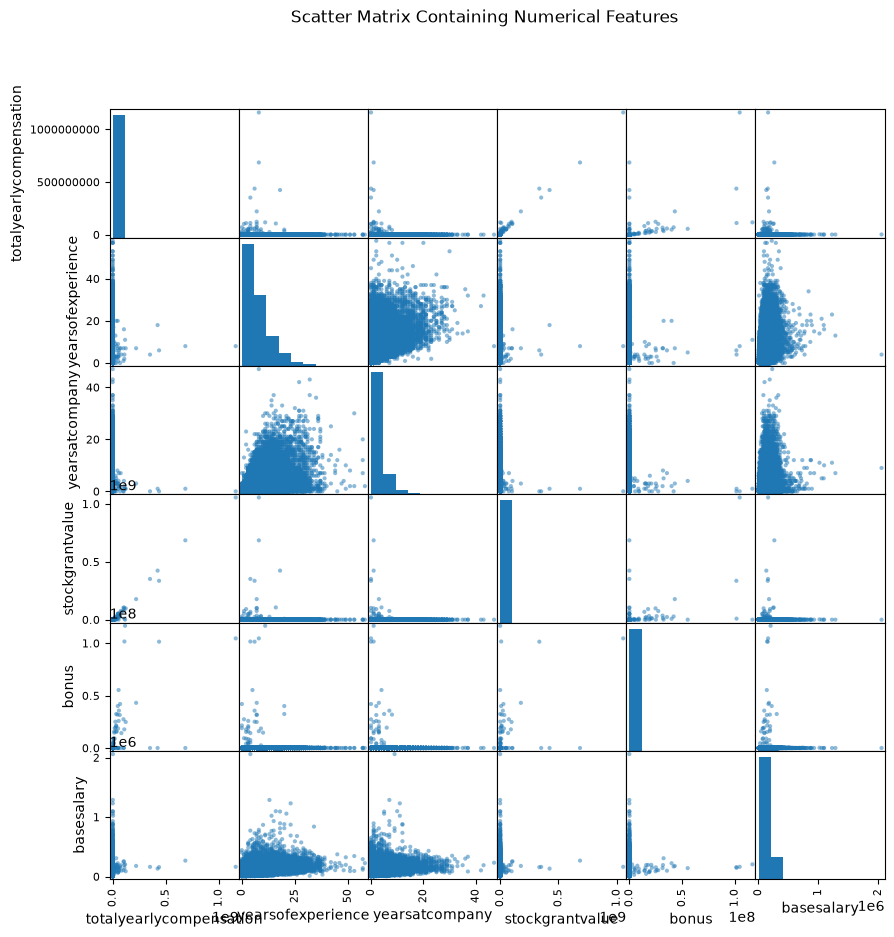

In [634]:
scatter_matrix(eda_df, figsize=(10, 10))
plt.suptitle("Scatter Matrix Containing Numerical Features")
plt.show()

I notice that it's hard to define any relationships looking at this scatter matrix. I will print the pearson correlation coefficients for the relationsips between our three monetary featuresand basesalary to investigate this.

In [635]:
print(f"totalyearlycompensation: {X_ms_train['totalyearlycompensation'].corr(y_ms_train):.3f}")

print(f"stockgrantvalue: {X_ms_train['stockgrantvalue'].corr(y_ms_train):.3f}")

print(f"bonus: {X_ms_train['bonus'].corr(y_ms_train):.3f}")

totalyearlycompensation: 0.020
stockgrantvalue: 0.011
bonus: 0.010


Examining the graph and the pearson correlation coefficients I see there is a problem. I expected the correlation between totalyearlycompensation and basesalary, stockgrantvalue and basesalary, and bonus and basesalary to all be much higher. I will have to revist the data cleaning stage and solve this problem.

# Revisting data cleaning

I believe this to again be a monetary unit scaling issue. What I previously did was find the boundary for basesalary and then multiply all records' monetary values by 1,000 if their basesalary was below the boundary. What seems to be happening is certain rows use inconsistent monetary unit scales for different monetary features. I thought of maybe finding a boundary for each individual monetary feature, but this seems impractical. This is because for features with smaller values like bonus it is likely that it would not be possible to establish a clear boundary.

From my previous analysis of percentiles I saw that roughly 1.1% of the values for each monetary value contained extremely large values (the values which we suspect are displayed in plain monetary units, not thousands), and that the jump usually occured just before the 99th percentile. I believe rather than trying to make all values consistent by scaling them (like multiplying all values below a boundary by 1,000), it would be most practical to remove all rows containing these extremely large values(those that we suspect are stored in plain monetary units). Since we have a dataset of 62,515, removing these rows would still leave a large dataset for us to work with. I will take this approach of removing extremely large values for each monetary feature. All rows with a value above a cutoff point for a monetary feature will be removed.

I acknowledge there are limitations to this approach:
- Since I will have to pick a cutoff point for each monetary feature (the boundary for which we will remove the row if the value is above it), it is possible that I will be removing genuine records from the dataset that just happen to be extremely high earners.
- It is also possible that some monetary values will remain in the dataset that use inconsitent monetary units. This may happen as some very low earners could lie below the cutoff.

I will begin this process by reading in a clean dataset and making all previous alterations I had done.

In [636]:
df = pd.read_csv(os.path.join(datasets_dir, "salaries.csv"))

In [637]:
df = df[(df["yearsofexperience"] != 90) & (df["yearsatcompany"] != 90)]

In [638]:
df = df.drop(columns=["otherdetails"])

In [639]:
df = df.drop(columns=["gender"])

In [640]:
df = df.dropna(subset=["company", "level", "dmaid"])

In [641]:
df = df[df["basesalary"] > 0].copy()

In [642]:
df = df.drop(columns=["rowNumber"])

I had previously established a boundary for basesalary at 1288 so we will use this as the cutoff. I will remove all rows with a basesalary greater than this value later on. I will next examine the percentiles for bonus in an attempt to establish a cutoff.

In [643]:
df["bonus"].quantile([0.9, 0.95, 0.96, 0.975, 0.98, 0.985, 0.9875, 0.99, 0.9925, 0.995, 0.9975, 1])

0.9000        47.000
0.9500        68.000
0.9600        76.000
0.9750        99.000
0.9800       116.000
0.9850       145.000
0.9875       173.000
0.9900       234.860
0.9925      5631.525
0.9950     15899.130
0.9975     29837.165
1.0000    384026.000
Name: bonus, dtype: float64

A jump occurs between 0.99 and 0.9925. I will use 223 as the cutoff.

I will next examine the percentiles for stockgrantvalue and establish a cutoff for it.

In [644]:
df["stockgrantvalue"].quantile([0.9, 0.95, 0.96, 0.975, 0.98, 0.985, 0.9875, 0.99, 0.9925, 0.995, 0.9975, 1])

0.9000        147.000
0.9500        231.000
0.9600        263.000
0.9750        346.000
0.9800        399.000
0.9850        507.000
0.9875        604.000
0.9900        970.740
0.9925      19010.150
0.9950      49224.350
0.9975     113808.845
1.0000    3140803.000
Name: stockgrantvalue, dtype: float64

A jump occurs between 0.99 and 0.9925. I will use 827 as the cutoff.

I will next examine the percentiles for totalyearlycompensation and againc create a cutoff.

In [645]:
df["totalyearlycompensation"].quantile([0.9, 0.95, 0.96, 0.975, 0.98, 0.985, 0.9875, 0.99, 0.9925, 0.995, 0.9975, 1])

0.9000        396.000
0.9500        514.000
0.9600        558.000
0.9750        691.000
0.9800        787.000
0.9850       1032.000
0.9875      11754.350
0.9900     110589.520
0.9925     164980.530
0.9950     221146.970
0.9975     313607.975
1.0000    3386013.000
Name: totalyearlycompensation, dtype: float64

A jump occurs between 0.9875 and 0.99. I will use 2034 as the cutoff.

I will now perform the alterations to the table to delete these rows.

In [646]:
df = df[df["basesalary"] < 1288].copy()
df = df[df["bonus"] < 223].copy()
df = df[df["stockgrantvalue"] < 827].copy()
df = df[df["totalyearlycompensation"] < 2034].copy()

In [647]:
df.shape

(59246, 14)

Above we see we still have a large dataset of over 60,000 rows even after these alterations.

I will now do again what I had previously done, up until the point where I revisted data cleaning.

In [648]:
features = ["timestamp", "company", "level", "title", "totalyearlycompensation", "location", "yearsofexperience",
            "yearsatcompany", "tag", "stockgrantvalue", "bonus" , "cityid", "dmaid"]

numeric_features = ["totalyearlycompensation", "yearsofexperience", "yearsatcompany", "stockgrantvalue", "bonus"]

nominal_features = ["company", "level", "title", "location", "tag", "cityid", "dmaid"]

timestamp_features = ["timestamp"]

X = df[features]

y = df["basesalary"]

In [649]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = rng)

In [650]:
X_ms_train, X_val, y_ms_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = rng)

In [651]:
eda_df = X_ms_train[numeric_features].copy()
eda_df["basesalary"] = y_ms_train

I will now recheck the pearson correlation coefficients to see has my data cleaning been successful.

In [652]:
print(f"totalyearlycompensation: {X_ms_train['totalyearlycompensation'].corr(y_ms_train):.3f}")

print(f"stockgrantvalue: {X_ms_train['stockgrantvalue'].corr(y_ms_train):.3f}")

print(f"bonus: {X_ms_train['bonus'].corr(y_ms_train):.3f}")

totalyearlycompensation: 0.791
stockgrantvalue: 0.351
bonus: 0.305


This makes much more sense and is encouraging. The correlation coefficients are now much stronger and around what we would expect them to be, so we can move on with our exploratory data analysis. We will go back to looking at the scatter matrix to analyse relationships between features, potentially finding some non-linear relationships.

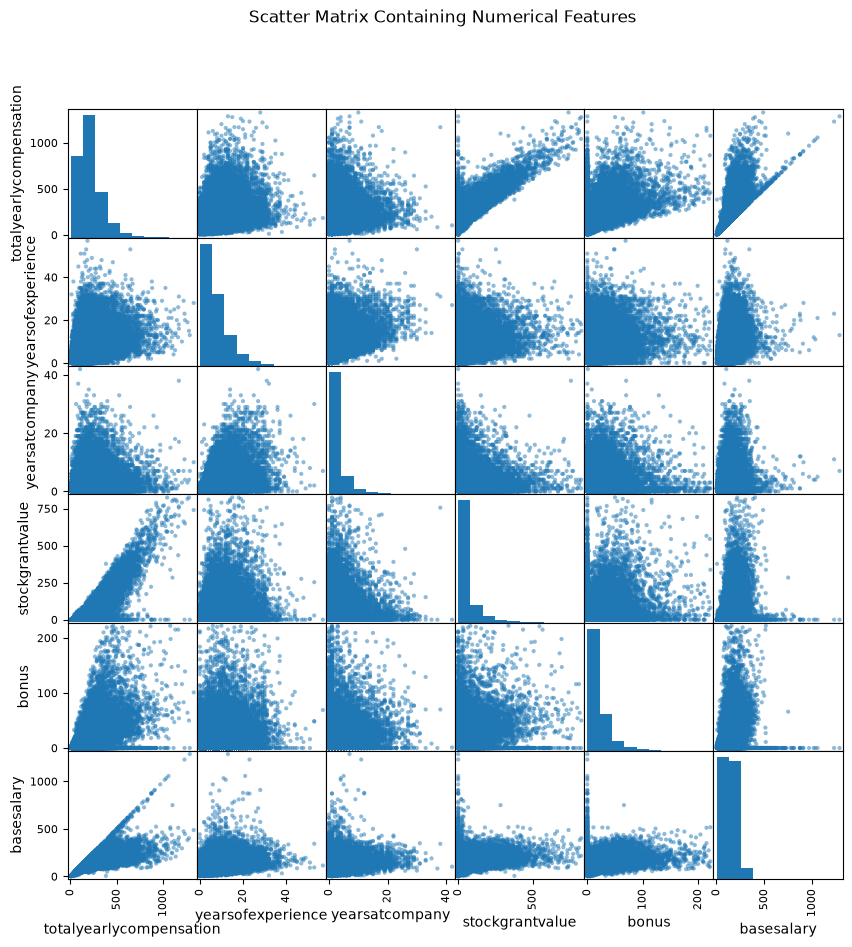

In [653]:
scatter_matrix(eda_df, figsize=(10, 10))
plt.suptitle("Scatter Matrix Containing Numerical Features")
plt.show()

From this we learn:
- totalyearlycompensation, stockgrantvalue and bonus all appear to have positive relationships with each other, some stronger than others.
- As yearsofexperience and yearsatcompany increase, basesalary doesn't necessarily increase. The values seem clustered to the left. They appear to have more of a quadratic relationship with basesalary rather than linear.
- Looking at the relationships between all features and basesalary, they appear to be more quadratic than linear.

I now want to use a heatmap to see the strength of linear relationships.

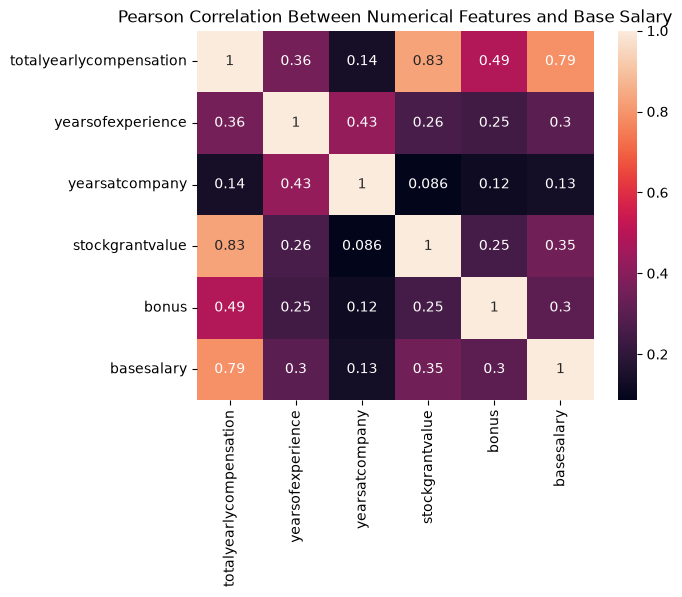

In [654]:
sns.heatmap(eda_df.corr(numeric_only=True), annot=True)
plt.title("Pearson Correlation Between Numerical Features and Base Salary")
plt.show()

What we can learn:
- Very strong positive correlation: totalyearlycompensation & stockgrantvalue, totalyearlycompensation & basesalary
- Moderately strong positive correlation: totalyearlycompensation & bonus, yearsofexperience & yearsatcompany
- Weak positive correlation: stockgrantvalue & basesalary, bonus & basesalary, yearsofexperience & basesalary, totalyearlycompensation & yearsofexperience

Next I want to investigate some of our nominal features. For each feature I will create a box plot of the 10 most common values for each feature. From this I can learn how useful the nominal features appear to be, how much the medians and distributions vary, and other things such as the spread of values or potential outliers.

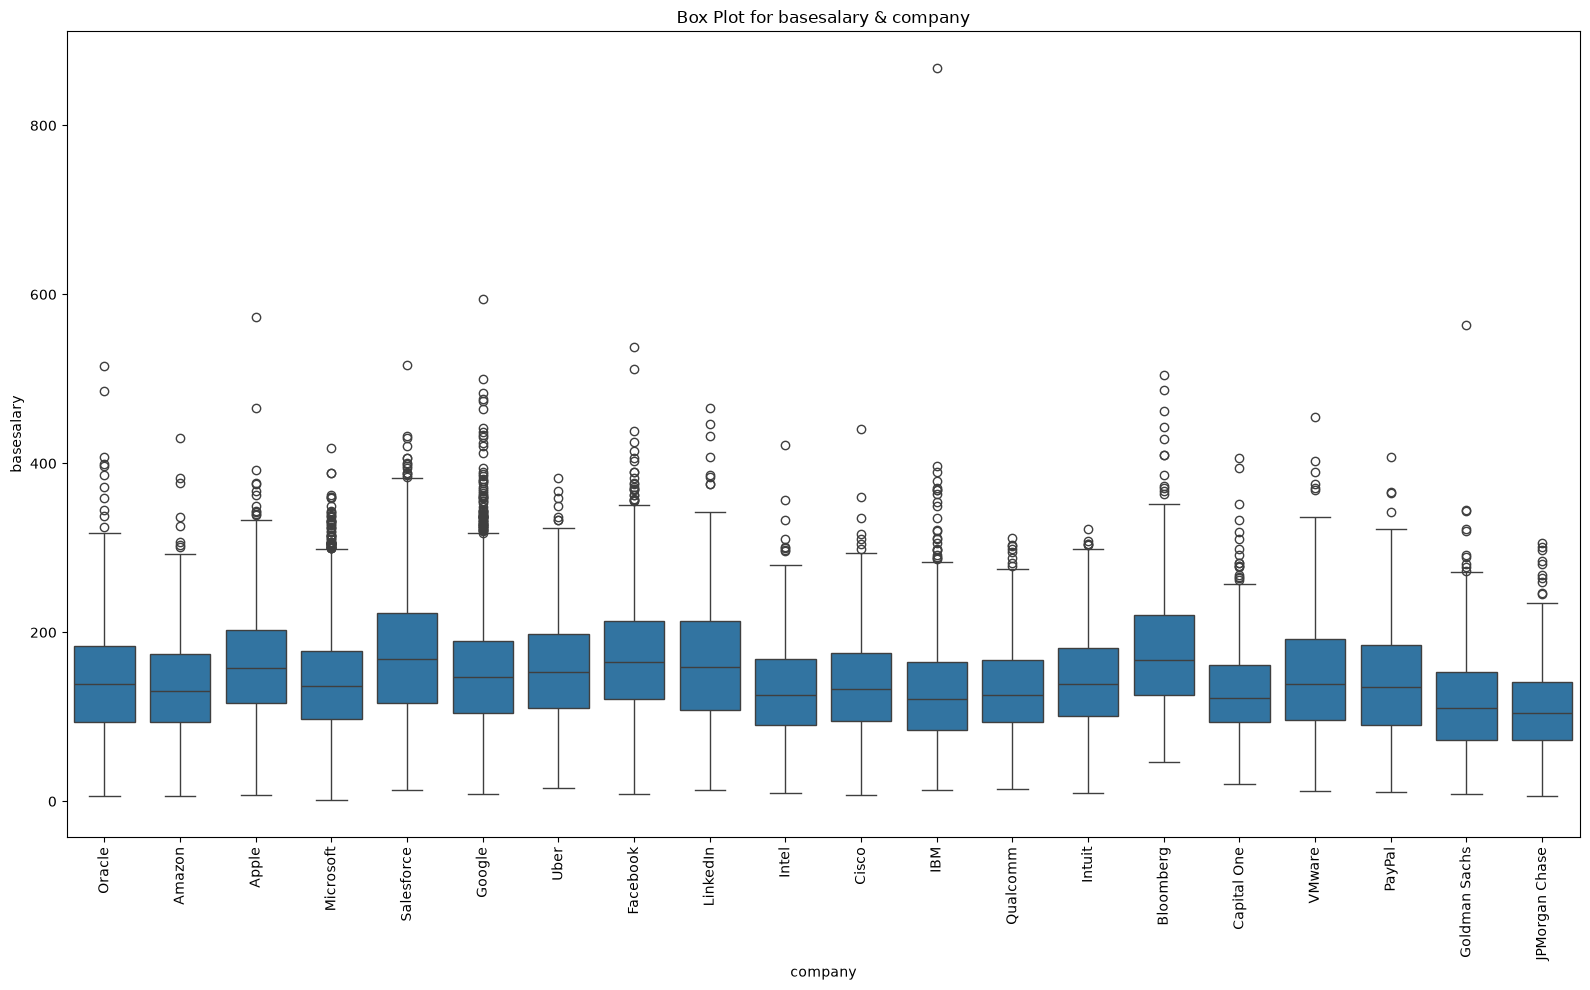

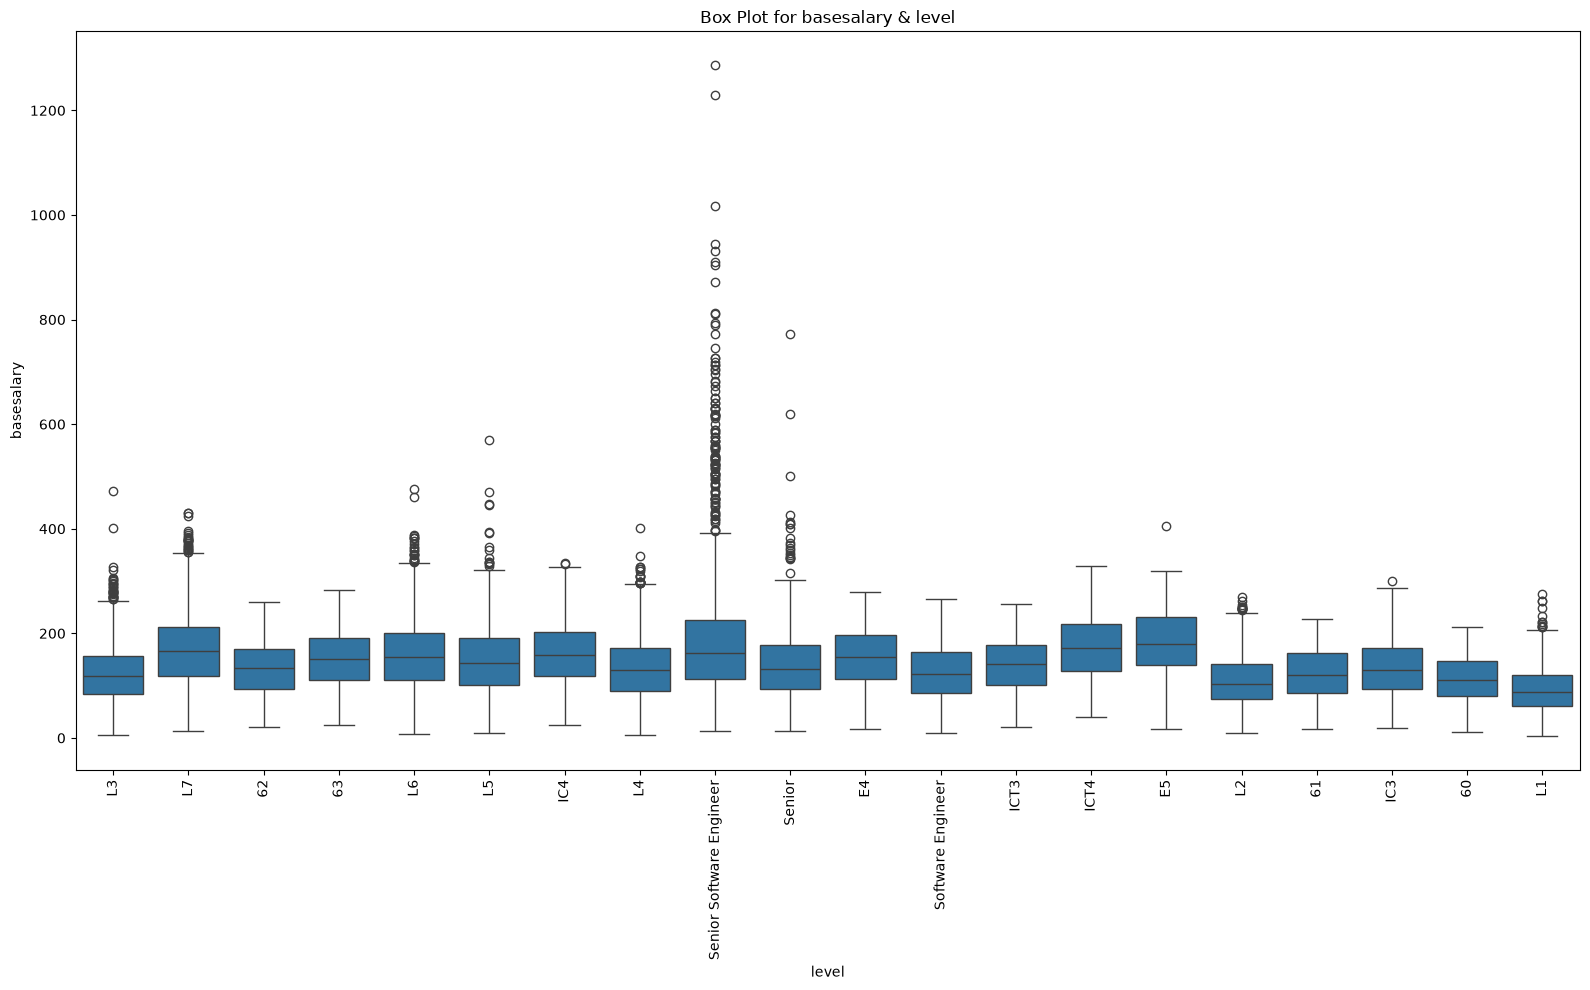

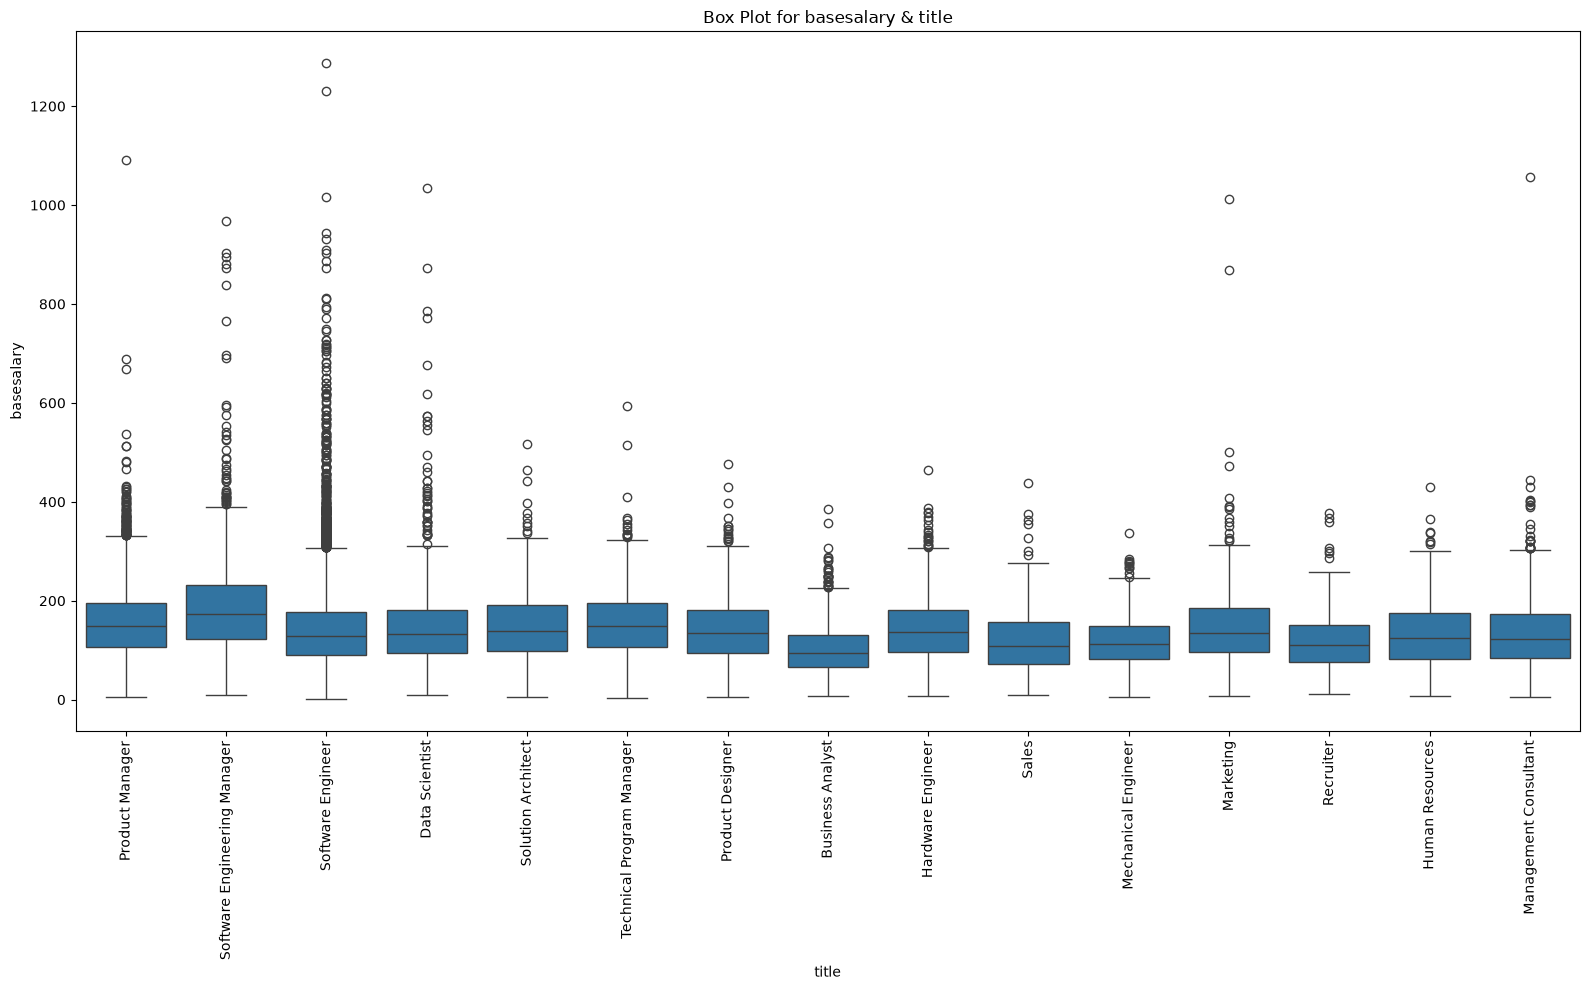

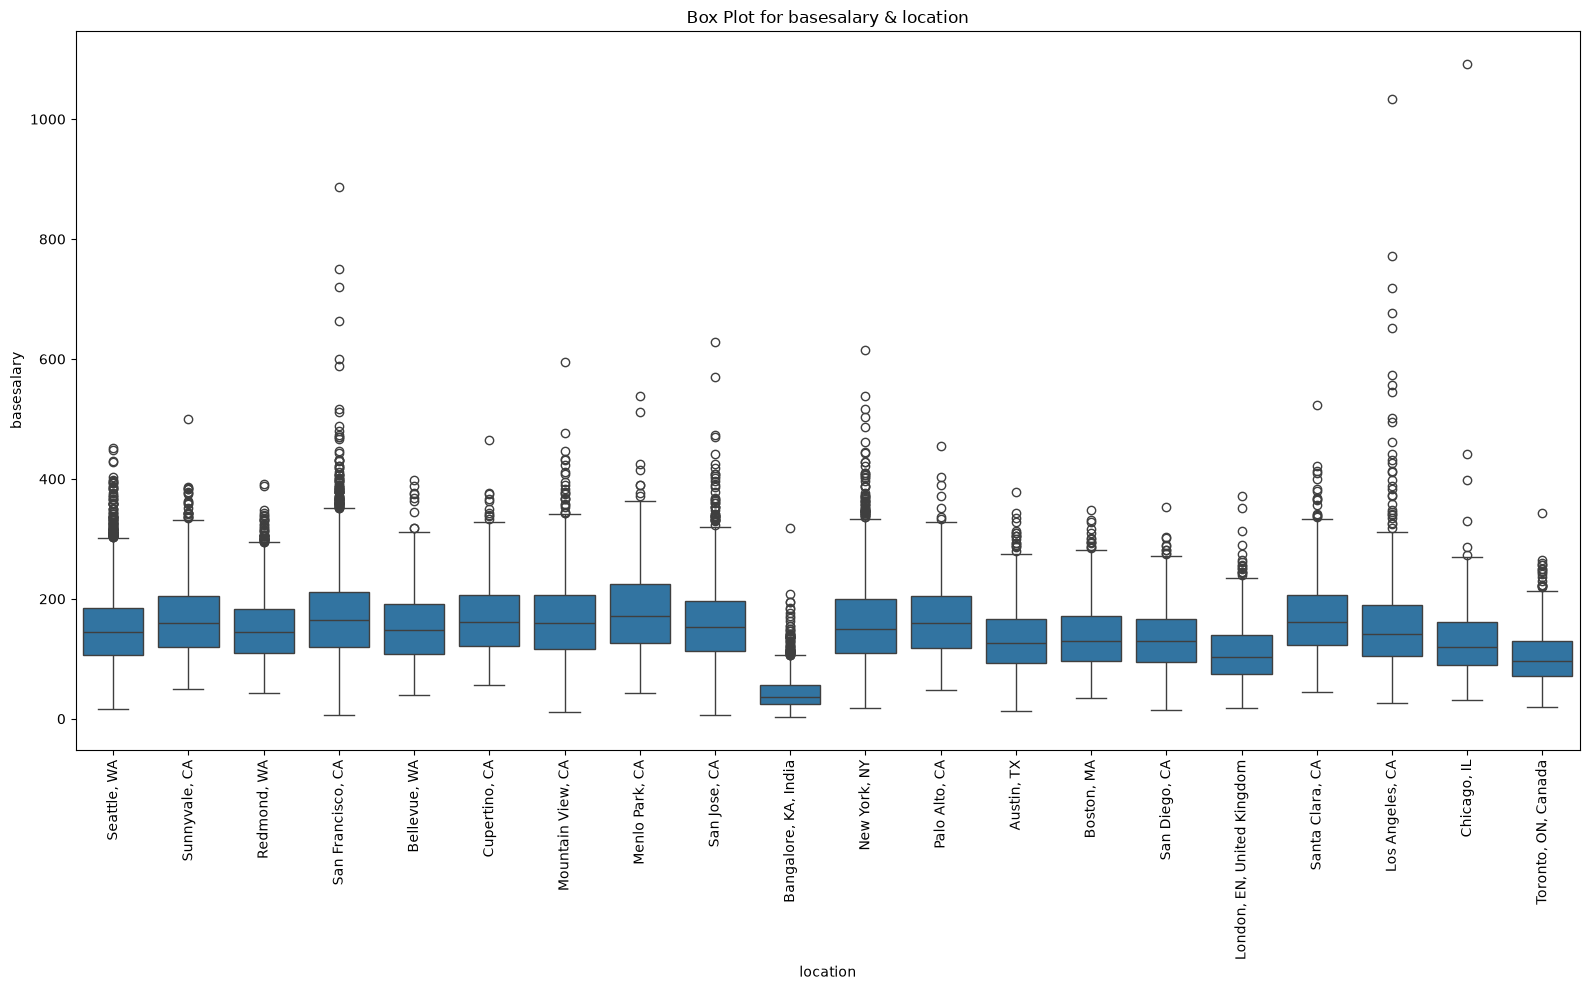

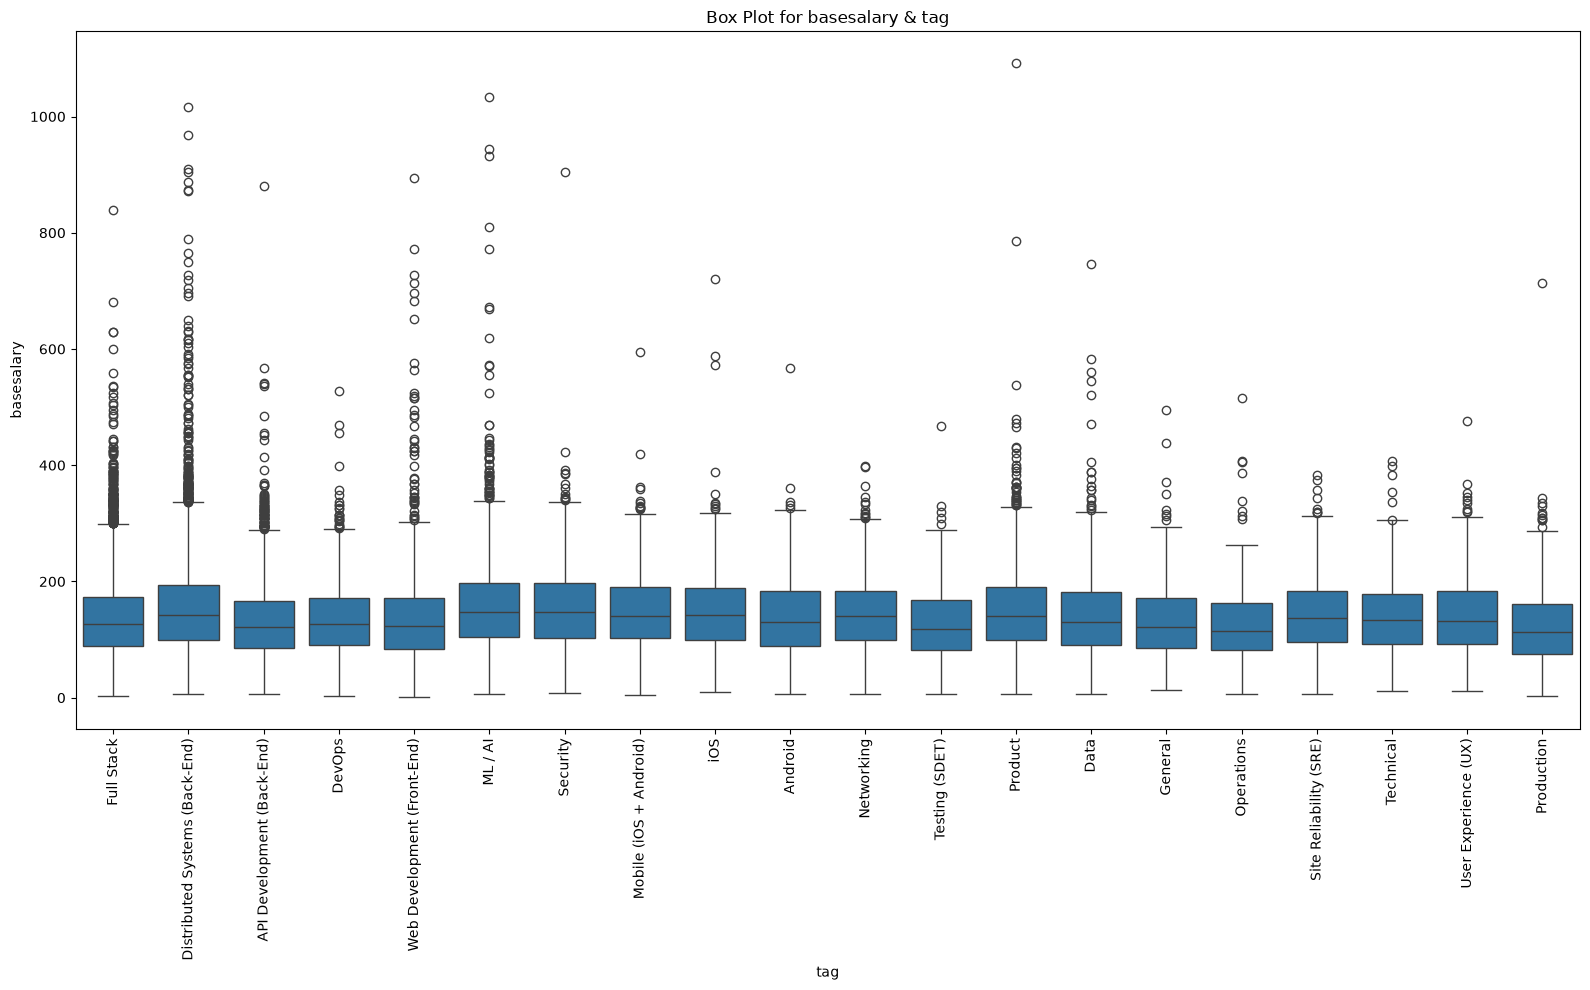

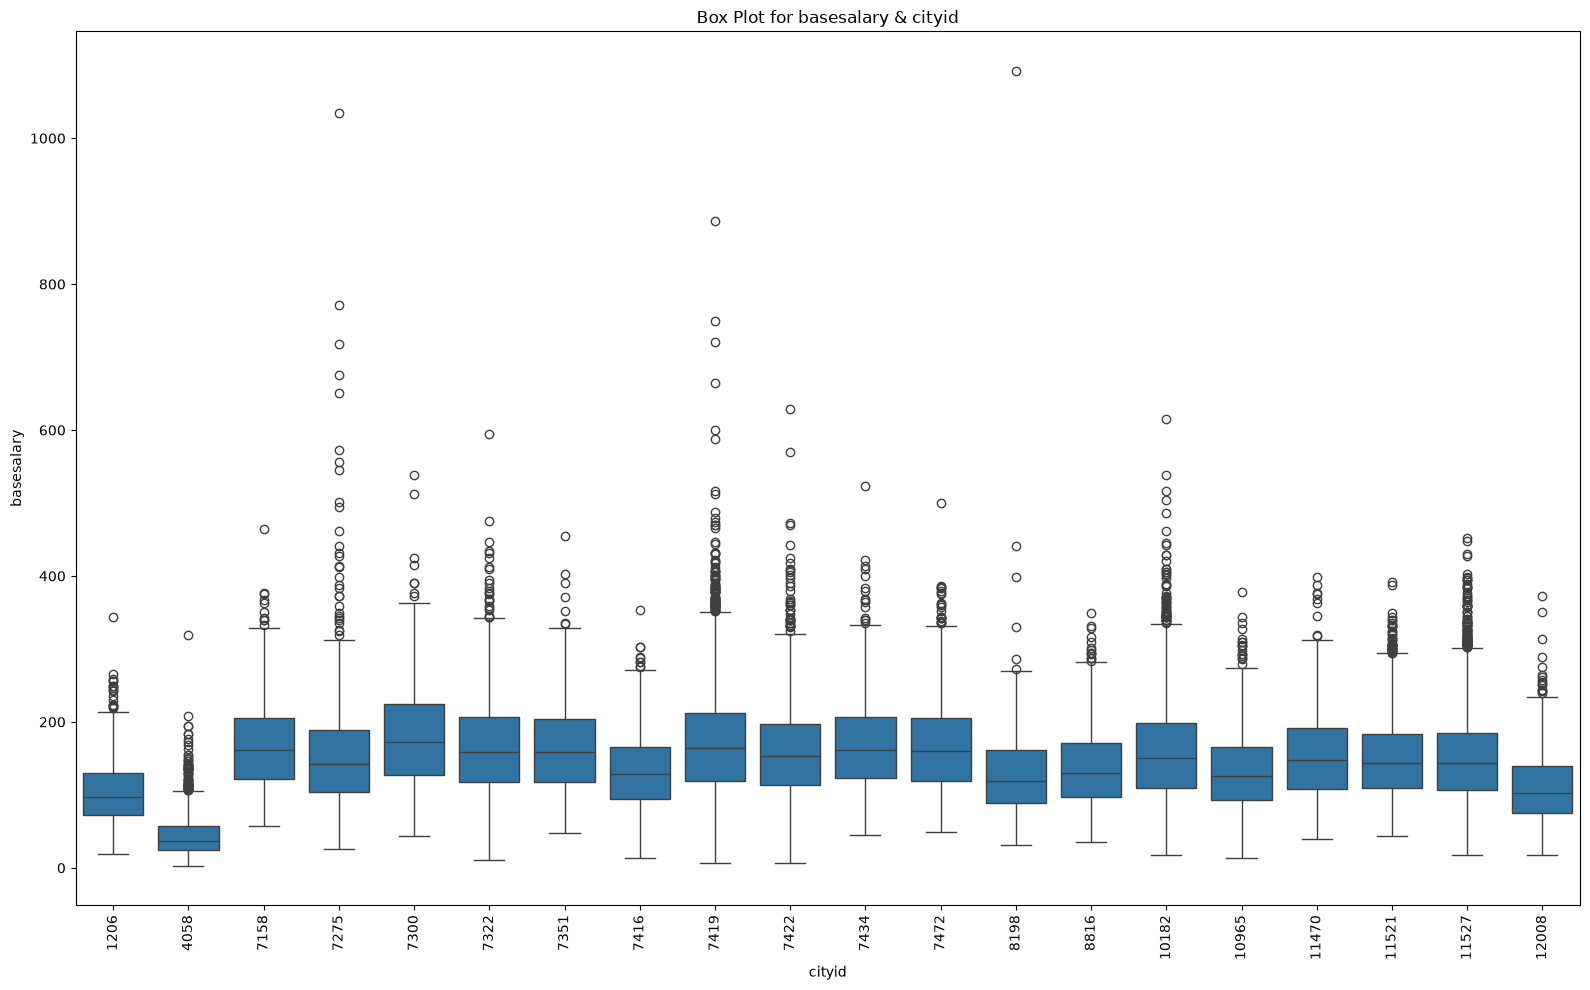

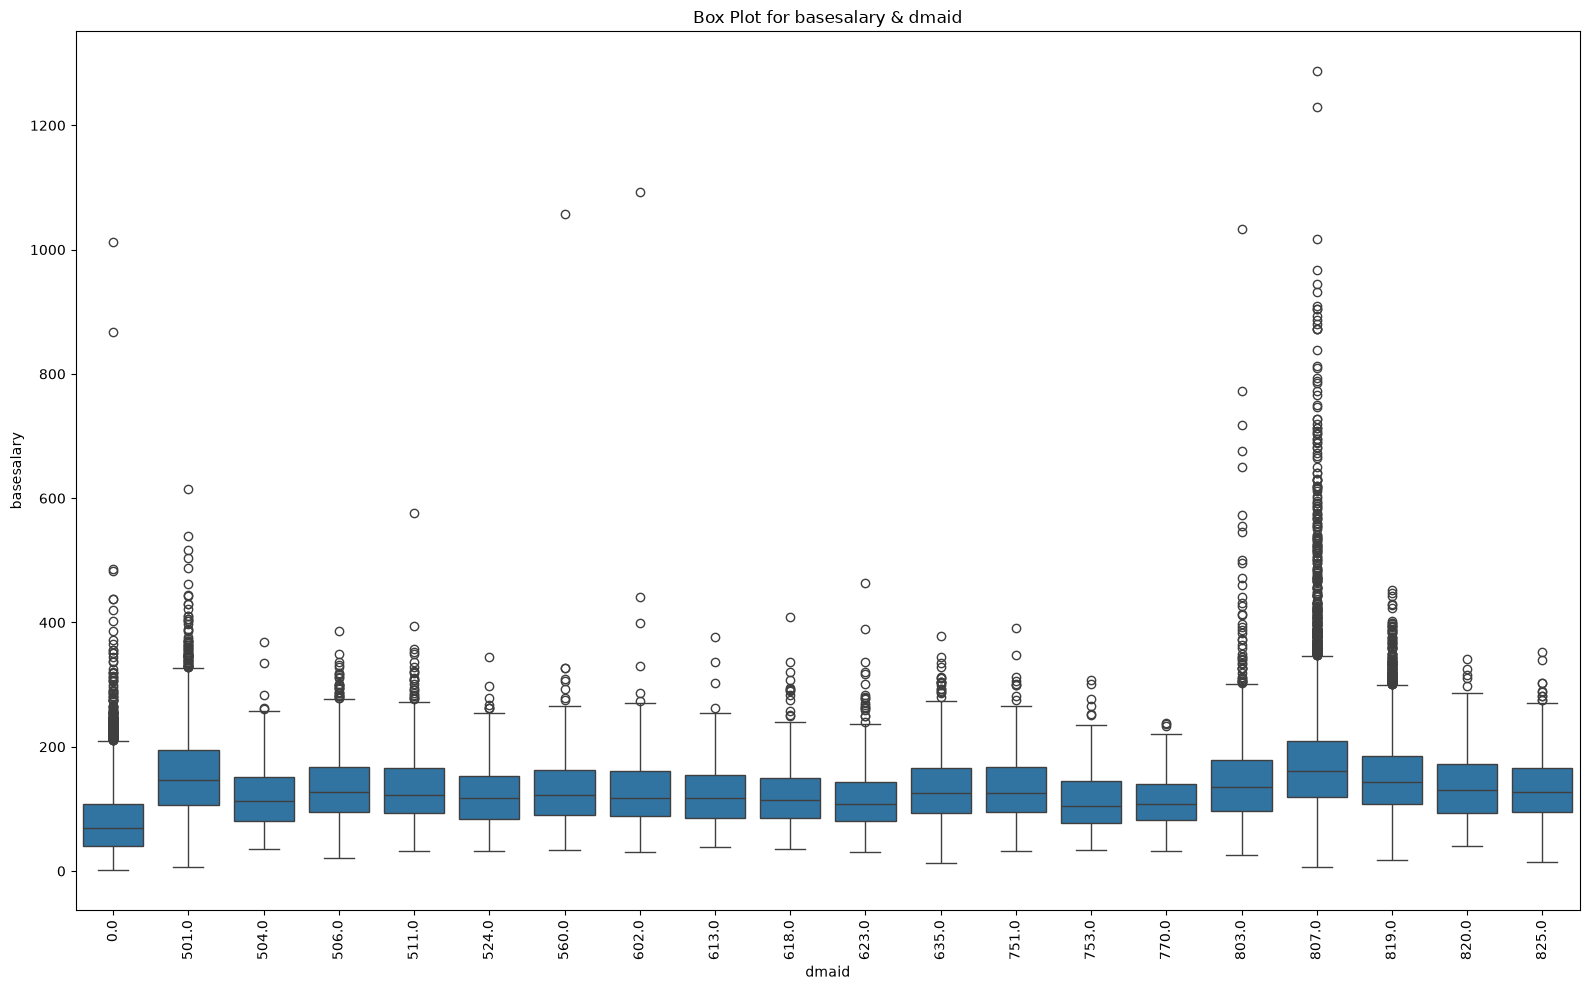

In [655]:
for feature in nominal_features:
    most_common = df[feature].value_counts().head(20).index
    boxplot_df = df[df[feature].isin(most_common)]

    plt.figure(figsize=(16, 10))
    sns.boxplot(data=boxplot_df,x=feature,y="basesalary",)
    
    plt.title(f"Box Plot for basesalary & {feature}")
    plt.xlabel(feature)
    plt.ylabel("basesalary")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

Looking at the medians and distributions of the categories in each graph I will give my opinion of the order if the nominal features from most useful to least useful:
1. company
2. cityid
3. location
4. level
5. Title
6. dmaid
7. tag

I am happy with 1-5 as upon examining the medians there seems to be a fair bit of variation which indicates potential feature usefulness. dmaid doesn't appear to be very useful at first, however we see dmaid with values of 0 have a low median basesalary compared to others. Since we previously discussed this is people living outside of the USA and it represents a sizeable portion of our dataset I believe this is important and useful. Therefore I will keep the dmaid feature. Looking at tag it doesn't seem to be too useful given the medians and distributions are similar, but I will keep it for now.

I am going to calculate how many values fall outside the interquartile range limits for my numerical features. This will be useful for later on, since it will give me a good indication for whether a winsorizer is needed or not.

In [656]:
q1 = X_ms_train[numeric_features].quantile(0.25)
q3 = X_ms_train[numeric_features].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

below = (X_ms_train[numeric_features] < lower).sum()
above = (X_ms_train[numeric_features] > upper).sum()

display(pd.DataFrame({f"Values below lower IQR limit": below, f"Values above upper IQR limit": above}))

,Values below lower IQR limit,Values above upper IQR limit
totalyearlycompensation,0,1472
yearsofexperience,0,1675
yearsatcompany,0,1381
stockgrantvalue,0,2839
bonus,0,1734


A small portion of values lie outside the range.

# Feature engineering

First of all I will remove totalyearlycompensation. This is as this feature contains and is derived from the target value itself (basesalary) which is target leakage.

Looking back at the assignment instructions it states *'You been offered a job! But how much should you get paid?'*. If we are after being offered a job and we dont't have the base salary then it would also usually mean we don't have the bonus or stock grant value either. These features may also be derived from basesalary such as for example being a percentage of it. For these reasons I will also remove these features. This means that I have previously unnecessarily removed many rows which are now valid. I removed these rows based on the cutoffs I defined for totalyearlycompensation, bonus, and stockgrantvalue. I will gather a fresh dataframe and perform all previous alterations without removing the unnecessary rows, before going any further. The cutoff for basesalary will still be used as it is our target value.

In [657]:
df = pd.read_csv(os.path.join(datasets_dir, "salaries.csv"))

In [658]:
df = df[(df["yearsofexperience"] != 90) & (df["yearsatcompany"] != 90)]

In [659]:
df = df.drop(columns=["otherdetails"])

In [660]:
df = df.drop(columns=["gender"])

In [661]:
df = df.dropna(subset=["company", "level", "dmaid"])

In [662]:
df = df[df["basesalary"] > 0].copy()

In [663]:
df = df.drop(columns=["rowNumber"])

In [664]:
df = df[df["basesalary"] < 1288].copy()

In [665]:
features = ["timestamp", "company", "level", "title", "totalyearlycompensation", "location", "yearsofexperience",
            "yearsatcompany", "tag", "stockgrantvalue", "bonus" , "cityid", "dmaid"]

numeric_features = ["totalyearlycompensation", "yearsofexperience", "yearsatcompany", "stockgrantvalue", "bonus"]

nominal_features = ["company", "level", "title", "location", "tag", "cityid", "dmaid"]

timestamp_features = ["timestamp"]

X = df[features]

y = df["basesalary"]

In [666]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = rng)

In [667]:
X_ms_train, X_val, y_ms_train, y_val = train_test_split(X_train, y_train, test_size = 0.25, random_state = rng)

I will create copies of our datasets so we can safely operate on them for feature engineering without affecting the original datasets.

In [668]:
X_ms_train_copy = X_ms_train.copy()
X_val_copy = X_val.copy()
X_test_copy = X_test.copy()

y_ms_train_copy = y_ms_train.copy()
y_val_copy = y_val.copy()
y_test_copy = y_test.copy()

Now I can remove the 3 monetary features.

In [669]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset.drop(columns=["totalyearlycompensation", "bonus", "stockgrantvalue"], inplace=True)
    
features = ["timestamp", "company", "level", "title", "location", "yearsofexperience",
            "yearsatcompany", "tag", "cityid", "dmaid"]

numeric_features = ["yearsofexperience", "yearsatcompany"]

Since timestamp is currently a string and not very useful to us I will extract the year from the string and turn it into a year feature. I believe this would be useful as it could capture inflation.

In [670]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset["year"] = pd.to_datetime(dataset["timestamp"], format="%m/%d/%Y %H:%M:%S", errors="coerce").dt.year
    dataset.drop(columns=["timestamp"], inplace=True)

features = ["year", "timestamp", "company", "level", "title", "location", "yearsofexperience", "yearsatcompany", "tag", "cityid", "dmaid"]

numeric_features = ["year", "yearsofexperience", "yearsatcompany"]

del timestamp_features

I will now perform interquartile range limit analysis for the new feature year, checking how many values lie outside the range limits.

In [671]:
q1 = X_ms_train_copy["year"].quantile(0.25)
q3 = X_ms_train_copy["year"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

below = (X_ms_train_copy["year"] < lower).sum()
above = (X_ms_train_copy["year"] > upper).sum()

display(pd.DataFrame({"Values below lower IQR limit": [below],"Values above upper IQR limit": [above]}))

,Values below lower IQR limit,Values above upper IQR limit
0,1650,0


Like previously a small portion of values lie outside the range. From my EDA I saw that there was a moderately strong positive correlation between yearsofexperience and yearsatcompany. Knowing this, it may be beneficial to engineer a new feature from these two. The feature I am going to create will be named tenureratio. It will be calculated by dividing yearsatcompany by yearsofexperience. I have chosen this ratio as it calculates the proportion of the person's career that they have spent at the current company. I believe the ratio may help predict salary as a higher ratio may indicate longer employee retention, which I suspect comes along with a higher salary. I will test my model with and without it later.

In [672]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset["tenureratio"] = dataset["yearsatcompany"] / dataset["yearsofexperience"].replace(0, np.nan)

features = ["year", "timestamp", "company", "level", "title", "location", "yearsofexperience", "yearsatcompany", "tenureratio", "tag", "cityid", "dmaid"]

numeric_features = ["year", "yearsofexperience", "yearsatcompany", "tenureratio"]

In [673]:
eda_df = X_ms_train_copy[numeric_features].copy()
eda_df["basesalary"] = y_ms_train_copy

I will create another heatmap to see the new feature's relationships.

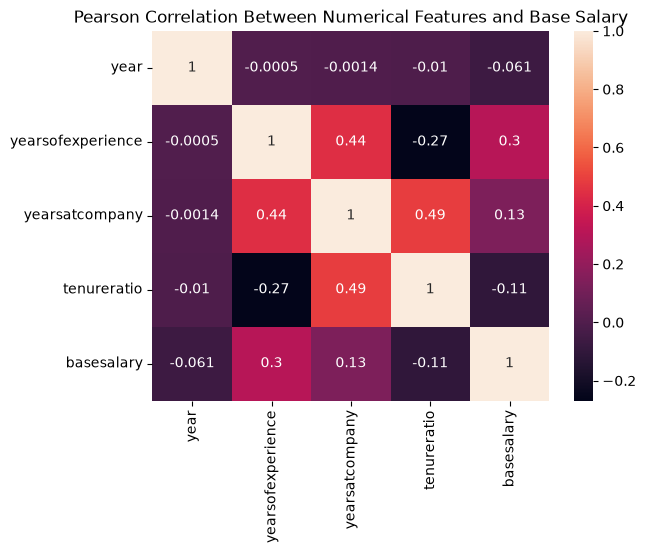

In [674]:
sns.heatmap(eda_df.corr(numeric_only=True), annot=True)
plt.title("Pearson Correlation Between Numerical Features and Base Salary")
plt.show()

My hypothesis of it predicting a higher salary seems to be incorrect, the opposite actually as it shows a very weak negative correlation.I will keep the feature included for now. I will persist with trying to engineer from a feature from yearsatcompany and yearsofexperience as I believe there is still potential for a new useful feature. Again focusing on these two features I will create a feature named previousexperience. It will be calculated by subtracting yearsatcompany from yearsofexperience. I believe this may be a useful feature as employees who were previously employed for a long time may bring more experience and skills to their new job, resulting in a higher salary.

In [675]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset["previousexperience"] = dataset["yearsofexperience"] - dataset["yearsatcompany"]

features = ["year", "timestamp", "company", "level", "title", "location", "yearsofexperience", "yearsatcompany", "tenureratio", "previousexperience", "tag", "cityid", "dmaid"]

numeric_features = ["year", "yearsofexperience", "yearsatcompany", "tenureratio", "previousexperience"]

In [676]:
eda_df = X_ms_train_copy[numeric_features].copy()
eda_df["basesalary"] = y_ms_train_copy

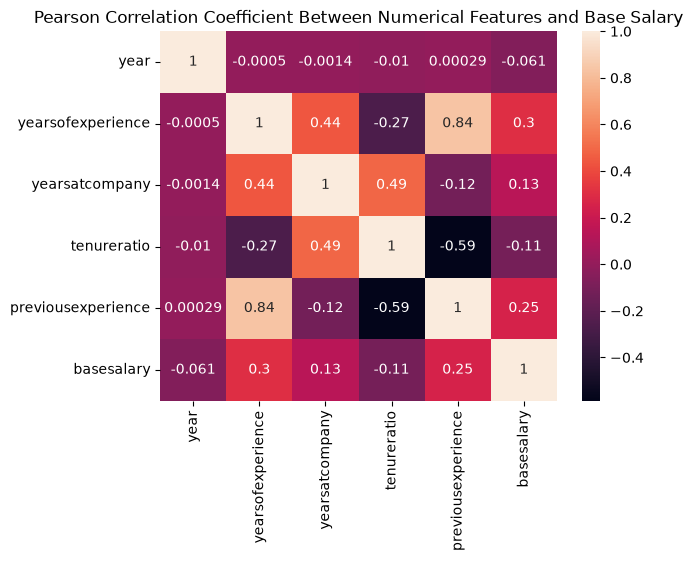

In [677]:
sns.heatmap(eda_df.corr(numeric_only=True), annot=True)
plt.title("Pearson Correlation Coefficient Between Numerical Features and Base Salary")
plt.show()

I will create a scatter plot between previousexperience and basesalary to investigate their relationship visually. I'm checking for a potential quadratic relationship.

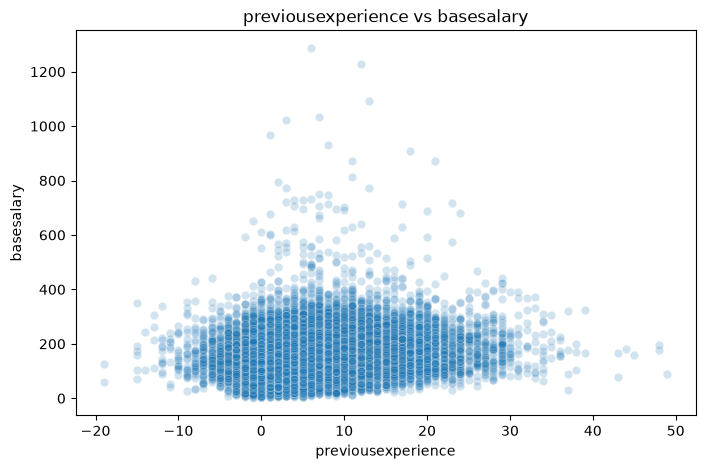

In [678]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x=X_ms_train_copy["previousexperience"], y=y_ms_train_copy, alpha=0.2)

plt.xlabel("previousexperience")
plt.ylabel("basesalary")
plt.title("previousexperience vs basesalary")
plt.show()

There's not an explicitly clear quadratic relationship, but I may investigate it further later. previousexperience has a weak positive correlation with basesalary, which indicates it could be a useful predictor for us going forward. It is also worth noting it has a very high positive correlation with yearsofexperience (as it is derived from it) but that doesn't necessarily mean it is a problem.

I'll now check how many values fall outside the interquartile range limits for the new feature previousexperience.

In [679]:
q1 = X_ms_train_copy["previousexperience"].quantile(0.25)
q3 = X_ms_train_copy["previousexperience"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

below = (X_ms_train_copy["previousexperience"] < lower).sum()
above = (X_ms_train_copy["previousexperience"] > upper).sum()

display(pd.DataFrame({"Values below lower IQR limit": [below],"Values above upper IQR limit": [above]}))

,Values below lower IQR limit,Values above upper IQR limit
0,35,1366


Again a small portion of values fall outside the range limits. Looking at the title feature I believe we can engineer a feature based on if someone is in a management role or not. This is as I expect a manager would usually get paid more due to usually carrying more responsibility. The new feature will be called managementrole. A row having a managementrole will be defined as manager/director/chief/ceo/president being present in their title. I am hoping this feature will help capture the relationship between management positions and basesalary compared to other positions and basesalary.

In [680]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset["managementrole"] = (dataset["title"].str.contains(r"\bmanager\b|\bdirector\b|\bchief\b|\bceo\b|\bpresident\b", case=False, na=False).astype(int))

features = ["year", "timestamp", "company", "level", "title", "location", "yearsofexperience", "yearsatcompany", "tenureratio", "previousexperience", "managementrole", "tag", "cityid", "dmaid"]

nominal_features = ["company", "level", "title", "location", "cityid", "dmaid", "managementrole"]

From previous EDA using the latest scatter matrix it appears both yearsofexperience and yearsatcompany may have a quadratic relationship with basesalary. I think it is also worth investigating if previousexperience has a quadratic relationship with basesalary. I will create yearsofexperiencesquared, yearsatcompanysquared, and previousexperiencesquared as features.

In [681]:
for dataset in [X_ms_train_copy, X_val_copy, X_test_copy]:
    dataset["yearsofexperiencesquared"] = dataset["yearsofexperience"] ** 2
    dataset["yearsatcompanysquared"] = dataset["yearsatcompany"] ** 2
    dataset["previousexperiencesquared"] = dataset["previousexperience"] ** 2

I will create a new scatter matrix to analyse the relationships between the new squared features and basesalary.

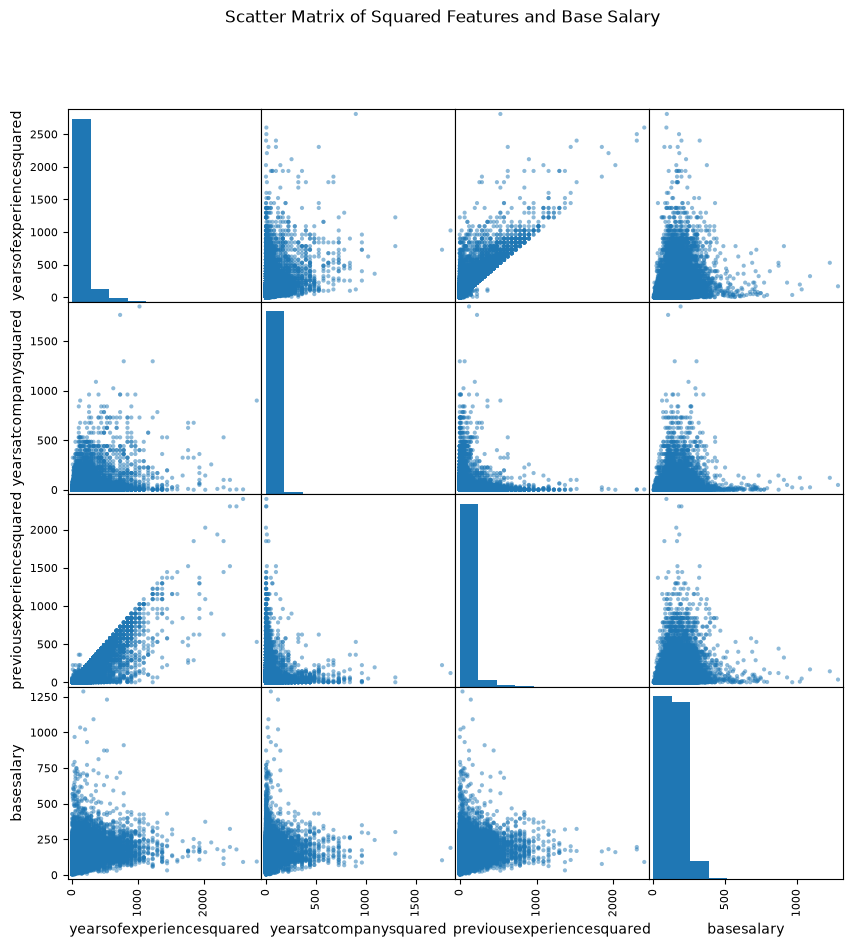

In [682]:
eda_df = X_ms_train_copy[["yearsofexperiencesquared", "yearsatcompanysquared", "previousexperiencesquared"]].copy()

eda_df["basesalary"] = y_ms_train_copy

scatter_matrix(eda_df, figsize=(10, 10))
plt.suptitle("Scatter Matrix of Squared Features and Base Salary")
plt.show()

The relationships between the squared features and basesalary appear to be more linear than the standard features and basesalary so this is promising.

Since I want to at least test my engineered features in the model using grid search I will write classes to insert them. These will be able to be toggled on or off through the grid search mechanism. I will choose not to carry tenureratio forward to the preprocessing stage as it appears the least useful of the engineered features, and this decision will cut down on some of the runtime when modelling.

In [683]:
class InsertYear(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["year"] = pd.to_datetime(X["timestamp"], format="%m/%d/%Y %H:%M:%S", errors="coerce").dt.year
        return X.drop(columns=["timestamp"])

In [684]:
class InsertPreviousExperience(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["previousexperience"] = X["yearsofexperience"] - X["yearsatcompany"]
        return X

In [685]:
class InsertManagementRole(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["managementrole"] = X["title"].str.contains(
                r"\bmanager\b|\bdirector\b|\bchief\b|\bceo\b|\bpresident\b",
                case=False, na=False).astype(int)
        return X

In [686]:
class InsertYearsOfExperienceSquared(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["yearsofexperiencesquared"] = X["yearsofexperience"] ** 2
        return X

In [687]:
class InsertYearsAtCompanySquared(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["yearsatcompanysquared"] = X["yearsatcompany"] ** 2
        return X

In [688]:
class InsertPreviousExperienceSquared(BaseEstimator, TransformerMixin):
    def __init__(self, insert=True):
        self.insert = insert
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X, y=None):
        X = X.copy()
        if self.insert:
            X["previousexperiencesquared"] = (X["yearsofexperience"] - X["yearsatcompany"]) ** 2
        return X

I will define my lists that I will use heading into preprocessing.

In [689]:
features = ["timestamp", "company", "level", "title", "location","yearsofexperience", "yearsatcompany", "tag", "cityid", "dmaid"]

numeric_features = ["timestamp", "yearsofexperience", "yearsatcompany"]

nominal_features = ["company", "level", "title", "location", "cityid", "dmaid"]

# Preprocessing

I am going to include a winsorizer that will clip values that fall outside of the range. Since I plan to run a grid search later it can be toggled on or off. The only drawback may be runtime. I made the choice to include it mainly based on the interquartile range limit analysis I had done in the EDA stage and feature engineering stage. Looking back at the findings, I see that for all my numerical features, there are at least 1,000 values that fall outside the range for each feature. This leads me to believe a winsorizer is worth investigating.

In [690]:
class Winsorizer(BaseEstimator, TransformerMixin):

    def __init__(self, winsorize=True, lower=0.25, upper=0.75, scaler=1.5):
        self.winsorize = winsorize
        self.lower = lower
        self.upper = upper
        self.scaler = scaler
        
    def fit(self, X, y=None):
        if self.winsorize:
            q1 = X.quantile(self.lower)
            q3 = X.quantile(self.upper)
            iqr =  q3 - q1 
            self.min = q1 - self.scaler * iqr
            self.max = q3 + self.scaler * iqr
        return self
    
    def transform(self, X, y=None):
        if self.winsorize:
            X = X.clip(self.min, self.max, axis=1)
        return X

For our numeric features I will scale them as part of the preprocessing pipeline. The scaling will be done later on in a grid search, evaluating the different types of scaling and picking the best one.

I will use one-hot-encoding for our nominal values. Before confirming this I calculated that we would have thousands of features, this may be problematic and lead towards overfitting since we would have such a large amount of features.

For the tag feature I will replace the missing values with "Unknown". I will opt against using the mode since there are a lot of unique tag values, so assigning the mode to some records could produce some misleading information. This means I have to configure the SimpleImputer to replace missing values with "Unknown" in the preprocessing pipeline.

I will build the preprocessor in steps for simplicity.

I will create a numeric pipeline which deals with my numeric features. I will pass insert = True to InsertYear() as I decided to extract year from the timestamp feature and want year as a permanent feature. This will help with reduce model runtime when using the grid search as year won't have to be toggled on and off. SimpleImputer replaces missing values with the median of that feature. I'm using the median as it isn't as sensitive to extreme values compared to the mean. I will ensure a pandas DataFrame is outputted as it would be easier to work with in the following steps.

In [691]:
numeric_pipeline = Pipeline([("year", InsertYear(insert = True)),
                             ("previousexperience", InsertPreviousExperience()),
                             ("yearsofexperiencesquared", InsertYearsOfExperienceSquared()),
                             ("yearsatcompanysquared", InsertYearsAtCompanySquared()),
                             ("previousexperiencesquared", InsertPreviousExperienceSquared()),
                             ("imputer", SimpleImputer(strategy = "median").set_output(transform="pandas")),
                             ("outliers", Winsorizer()),
                             ("scaler", None)])

Next I will create  the nominal pipeline for nominal features. I will use one-hot-encoding for these features, resulting in thousands of new rows. I will set drop = "if_binary" to drop one of the columns if a feature is binary. handle_unknown = "ignore" will help us when encountering a category that didn't appear in our training data.

In [692]:
nominal_pipeline = Pipeline([("managementrole", InsertManagementRole()),
                             ("encoder", OneHotEncoder
                             (drop = "if_binary",
                             handle_unknown = "ignore"))])

I will now start combining pipelines and create the final preprocessor. I will use my already created numeric and nominal pipelines. I will also create a pipeline handling the tag feature. I will use SimpleImputer to replace all missing values for tag with "Unknown". I am using "Unknown" instead of the mode, since tag has a lot of unique values and replacing missing values with the mode would result in many misleading values. I will also use one-hot-encoding which will result in more new columns. I will drop all unused columns.

In [693]:
preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_features),
                                  ("tag", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                  ("encoder", OneHotEncoder(
                                  drop="if_binary",
                                  handle_unknown="ignore"))]),
                                  ["tag"]),
                                  ("nom", nominal_pipeline, nominal_features)],
                                  remainder="drop")

I'll check how many features my preprocessor produces.

In [694]:
print(preprocessor.fit_transform(X_ms_train).shape)

(35716, 7870)


8,007 features for 37,096 rows may be problematic due to the risk of overfitting, and dimensionality reduction may be used later.

# Model Selection

We will first use a dummy regressor as a performance evaluator. We will use this as a baseline to compare our model against. As I said at the beginning, I will use root mean squared error (RMSE) as the main performance measure since:
1. I have cleaned the dataset to adddress potentially erroneous values, and also have a winsorizer that can be toggled on or off, to limit and clip extreme values.
2. RMSE penalises larger errors more that MAE. Since we are predicting salary I believe this will be more useful since we want to penalise larger errors.

In [695]:
dummy_regressor = DummyRegressor()

dummy_regressor.fit(X_ms_train, y_ms_train)

y_train_pred_dummy = dummy_regressor.predict(X_ms_train)
y_val_pred_dummy = dummy_regressor.predict(X_val)

print(f"Training set RMSE: {math.sqrt(mean_squared_error(y_ms_train, y_train_pred_dummy)):.2f}")
print(f"Validation set RMSE: {math.sqrt(mean_squared_error(y_val, y_val_pred_dummy)):.2f}")

Training set RMSE: 71.56
Validation set RMSE: 70.88


A validation set RMSE of 70.88 is a poor result which is expected from the dummy.

I want to now create a grid search function. Since one of the parameters are cv, and its default value is 5 this is problematic as I am using holdout with a 60/20/20 split. To solve this I first imported PrefedinedSplit from sklearn.model_selection in the imports cell near the top. I will concatenate my training examples with validation examples, and my training values with validation values.

In [696]:
X_search = pd.concat([X_ms_train, X_val])
y_search = pd.concat([y_ms_train, y_val])

I will then use PredefinedSplit to use the first 60% of the original dataset as the training set, and next 20% of the original dataset for validation. Here I assign -1 to all training records, and 0 to all validation records.

In [697]:
cv = PredefinedSplit(test_fold=[-1] * len(X_ms_train) + [0] * len(X_val))

Next I will create the grid search function to find the best hyperparameters for each model. Our preprocessor and a predictor will be combined into a single pipeline. After running this function I can find out the best combination of hyperparameters for a certain model.

In [698]:
def grid_search(preprocessor, predictor, param_grid, cv, metric, X_train, y_train):
    model = Pipeline([("preprocessor", preprocessor),
                      ("predictor", predictor)])

    gs = GridSearchCV(model,
                      param_grid,
                      scoring=metric,
                      cv=cv,
                      n_jobs=-1,
                      return_train_score=True)

    gs.fit(X_train, y_train)
    
    return gs

I first attempted to run a KNN regressor grid search but it took far too long to run. I suspect this is because of the large amount of features we now have, which vastly increases the computational cost of each distance calculation being performed in a KNN regressor. This is another reason I may implement dimensionality reduction later.

I will now run a ridge regression grid search. I have chosen ridge regression as it is relatively efficient to run on datasets with a large amount of features, and it uses regularization to prevent overfitting with our large amount of features. I will not toggle eveything, as it will create a large amount of combinations and we have runtime constraints.

In [699]:
ridge_regression_gs = grid_search(preprocessor=preprocessor,
                                  predictor=Ridge(),
                                  param_grid={"preprocessor__num__previousexperience__insert": [True, False],
                                             "preprocessor__num__yearsofexperiencesquared__insert": [True],
                                             "preprocessor__num__yearsatcompanysquared__insert": [True],
                                             "preprocessor__num__previousexperiencesquared__insert": [True, False],
                                             "preprocessor__nom__managementrole__insert": [True, False],
                                             "preprocessor__num__outliers__winsorize": [True, False],
                                             "preprocessor__num__scaler": [RobustScaler()],
                                             "predictor__alpha": [1, 10, 100]},
                                              cv=cv,
                                              metric="neg_root_mean_squared_error",
                                              X_train=X_search,
                                              y_train=y_search)

print(ridge_regression_gs.best_params_)

train_rmse = -ridge_regression_gs.cv_results_["mean_train_score"][ridge_regression_gs.best_index_]
val_rmse = -ridge_regression_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__alpha': 10, 'preprocessor__nom__managementrole__insert': True, 'preprocessor__num__outliers__winsorize': False, 'preprocessor__num__previousexperience__insert': False, 'preprocessor__num__previousexperiencesquared__insert': True, 'preprocessor__num__scaler': RobustScaler(), 'preprocessor__num__yearsatcompanysquared__insert': True, 'preprocessor__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 49.28
Validation set RMSE: 51.19


The validation RMSE of 51.19 is a sizeable improvement over our dummy's validation RMSE of 70.88.

I will next train a decision tree regressor. I have chosen a decision tree regressor as it can capture non-linear relationships which may not be captured in my ridge regressor. I won't use a scaler here as splits are decided by thresholds instead of things like distance calculations.

In [700]:
decision_tree_gs = grid_search(preprocessor=preprocessor,
                               predictor=DecisionTreeRegressor(random_state=2),
                               param_grid={"preprocessor__num__previousexperience__insert": [True, False],
                                           "preprocessor__num__yearsofexperiencesquared__insert": [True],
                                           "preprocessor__num__yearsatcompanysquared__insert": [True],
                                           "preprocessor__num__previousexperiencesquared__insert": [True, False],
                                           "preprocessor__nom__managementrole__insert": [True, False],
                                           "preprocessor__num__outliers__winsorize": [True, False],
                                           "preprocessor__num__scaler": [None],
                                           "predictor__max_depth": [7, 10, 13]},
                                           cv=cv,
                                           metric="neg_root_mean_squared_error",
                                           X_train=X_search,
                                           y_train=y_search)

print(decision_tree_gs.best_params_)

train_rmse = -decision_tree_gs.cv_results_["mean_train_score"][decision_tree_gs.best_index_]
val_rmse = -decision_tree_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__max_depth': 10, 'preprocessor__nom__managementrole__insert': False, 'preprocessor__num__outliers__winsorize': False, 'preprocessor__num__previousexperience__insert': True, 'preprocessor__num__previousexperiencesquared__insert': False, 'preprocessor__num__scaler': None, 'preprocessor__num__yearsatcompanysquared__insert': True, 'preprocessor__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 51.97
Validation set RMSE: 54.95


The decision tree regressor did better than the dummy regressor, but worse than the ridge regressor.

I will next plot validation curves of my two models that I have so far created. I will do this to get an idea of if we are overfitting or underfitting. I'll first create a reusable function for plotting the validation curves.

In [701]:
def plot_validation_curve(x_range, train_errors, val_errors, invert_axis=False):
    fig = plt.figure()
    ax = plt.axes()
    plt.xlabel("complexity")
    if invert_axis:
        ax.invert_xaxis()
    plt.ylabel("error")
    plt.plot(x_range, train_errors, label = "training error", color = "red")
    plt.plot(x_range, val_errors, label="validation error", color = "gold")
    plt.legend()

Next I'll create a helper function. This will extract the training and validation errors from my current results. It takes in a grid search object and hyperparameter to investigate, and finds the result for each tested value of that hyperparameter. It will then sort by the selected hyperparameter and return its values with its corresponding training and validation errors, being able to be passed to the validation curve plotting function.

In [702]:
def get_validation_errors(gs, parameter):
    values = []
    training_errors = []
    validation_errors = []

    for i, params in enumerate(gs.cv_results_["params"]):
        matches = True

        for key in gs.best_params_:
            if key != parameter:
                if str(params[key]) != str(gs.best_params_[key]):
                    matches = False
                    break

        if matches:
            values.append(params[parameter])
            training_errors.append(-gs.cv_results_["mean_train_score"][i])
            validation_errors.append(-gs.cv_results_["mean_test_score"][i])

    order = np.argsort(values)

    values = np.array(values)[order]
    training_errors = np.array(training_errors)[order]
    validation_errors = np.array(validation_errors)[order]

    return values, training_errors, validation_errors

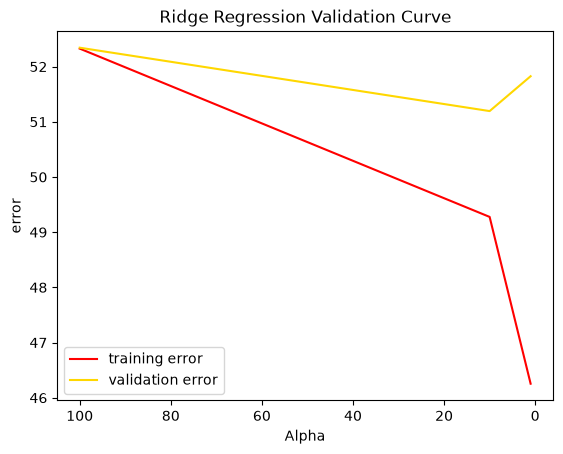

In [703]:
alphas, train_errors, val_errors = get_validation_errors(ridge_regression_gs, "predictor__alpha")

plot_validation_curve(x_range=alphas,train_errors=train_errors,val_errors=val_errors,invert_axis=True)

plt.xlabel("Alpha")
plt.title("Ridge Regression Validation Curve")
plt.show()

We can see here when alpha is higher the training error and validation error is higher due to more regularization, suggesting underfitting. When alpha is very low the training error is low and validation error is high suggesting overfitting. The value our grid search chose of 10 seems to be around the sweet spot as it results in the lowest validation erorr.

Next I will plot the validation curve for the decision tree regressor, testing for different maximum depths.

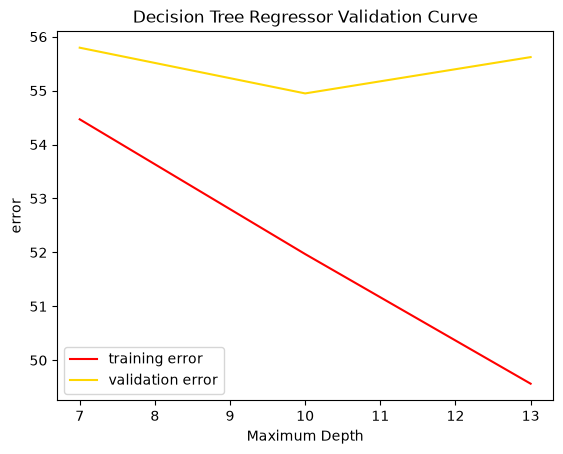

In [704]:
depths, train_errors, val_errors = get_validation_errors(decision_tree_gs, "predictor__max_depth")

plot_validation_curve(x_range=depths,train_errors=train_errors,val_errors=val_errors)

plt.xlabel("Maximum Depth")
plt.title("Decision Tree Regressor Validation Curve")
plt.show()

Here we can see when the maximum depth is low that the training and validation error is high, again suggesting underfitting is occuring since the tree is quite simple. When the maximum depth is high the training error is low and validation error is high again this time suggesting overfitting. Like above our maximum depth of 10 appears to be the sweet spot as it comes with the lowest validation error.

Next I want to reduce the amount of features I have. This is as we currently have a large amount of features relative to the amount of rows. Dimensionality reduction would help reduce the risk of overfitting, and reduce runtime. Sequential feature selection and filter methods are other options for feature amount reduction. I will not use sequential feature selection as there are currently too many features and would be very computationally expensive. I previously discussed implementing dimensionality reduction, but instead I will choose filter methods as I feel it is more suitable. I will choose this as a filter method such as SelectKBest keeps our original features, instead of combining existing ones like PCA. Filter methods are also generally less computationally expensive which is a big help considering the already large amount of features we have.

Now I will create a new preprocessing pipeline. It will include SelectKBest for feature selection. I will use clone() to reuse the previous best preprocessing configuration from the previous ridge regressor. This allows me to keep the previous best preprocessing configuration. I'll then sue SelectKBest with f_regression, ranking features based on their relationships with basesalary. Finally I'll use a grid search to find out how many of these features should be used to get the lowest possible RMSE.

In [705]:
skb_preprocessor = Pipeline([("features", clone(ridge_regression_gs.best_estimator_.named_steps["preprocessor"])),
                             ("f_selector", SelectKBest(score_func=f_regression))])

Next I'll run a grid search, testing various amounts of feature being included.

In [706]:
skb_ridge_gs = grid_search(preprocessor=skb_preprocessor,
                           predictor=Ridge(alpha=10),
                           param_grid={"preprocessor__f_selector__k": [100, 500, 1000, 3000, 5000, 7000, "all"]},
                           cv=cv,
                           metric="neg_root_mean_squared_error",
                           X_train=X_search,
                           y_train=y_search)

print(skb_ridge_gs.best_params_)

training_rmse = -skb_ridge_gs.cv_results_["mean_train_score"][skb_ridge_gs.best_index_]
validation_rmse = -skb_ridge_gs.best_score_

print(f"Training set RMSE: {training_rmse:.2f}")
print(f"Validation set RMSE: {validation_rmse:.2f}")

{'preprocessor__f_selector__k': 7000}
Training set RMSE: 49.36
Validation set RMSE: 51.19


We see that the model performed best with 7,000 features. I'll create a new skb preprocessing pipeline.

In [707]:
skb_preprocessor = Pipeline([("features", clone(preprocessor)), ("f_selector", SelectKBest(score_func=f_regression, k=7000))])

I will next create a new preprocessing pipeline for the decision tree model. SelectFromModel will estimate feature importance based on a trained model. I will use a RandomForestRegressor to estimate these importances. I set the threshold to negative infinity to control the amount of features through max_features in the grid search.

In [708]:
sfm_preprocessor = Pipeline([("features", clone(decision_tree_gs.best_estimator_.named_steps["preprocessor"])),
                             ("f_selector", SelectFromModel(
                                estimator=RandomForestRegressor(
                                n_estimators=20,
                                max_depth=10,
                                random_state=rng,
                                n_jobs=1),
                                threshold=-np.inf))])

In [709]:
sfm_tree_gs = grid_search(preprocessor=sfm_preprocessor,
                          predictor=DecisionTreeRegressor(max_depth=10, random_state=2),
                          param_grid={"preprocessor__f_selector__max_features": [50, 100, 250]},
                          cv=cv,
                          metric="neg_root_mean_squared_error",
                          X_train=X_search,
                          y_train=y_search)

print(sfm_tree_gs.best_params_)

training_rmse = -sfm_tree_gs.cv_results_["mean_train_score"][sfm_tree_gs.best_index_]
validation_rmse = -sfm_tree_gs.best_score_

print(f"Training set RMSE: {training_rmse:.2f}")
print(f"Validation set RMSE: {validation_rmse:.2f}")

{'preprocessor__f_selector__max_features': 250}
Training set RMSE: 51.98
Validation set RMSE: 55.12


We learn here that we can retain 250 features, and have a marginally worse validation set RMSE. SelectFromModel did well to reduce dimensionality which keeping the predictive accuracy extremely similar. This leads me to think a small feature set for a decision tree regressor is sufficient to retain accuracy.

I will next investigate an ensemble like a random forest and see if it improves predictive accuracy.

In [710]:
random_forest_gs = grid_search(
    preprocessor=preprocessor,
    predictor=RandomForestRegressor(random_state=2, n_jobs=1),
    param_grid={
        "predictor__n_estimators": [20],
        "predictor__max_depth": [10]
    },
    cv=cv,
    metric="neg_root_mean_squared_error",
    X_train=X_search,
    y_train=y_search
)

print(random_forest_gs.best_params_)

training_rmse = -random_forest_gs.cv_results_["mean_train_score"][random_forest_gs.best_index_]
validation_rmse = -random_forest_gs.best_score_

print(f"Training set RMSE: {training_rmse:.2f}")
print(f"Validation set RMSE: {validation_rmse:.2f}")

{'predictor__max_depth': 10, 'predictor__n_estimators': 20}
Training set RMSE: 51.23
Validation set RMSE: 54.11


We can see that the random forest improves on the decision tree but still isn't better than the ridge regressor. Since the ridge regressor is the most accurate so far, I will focus on optimising that and making it as accurate as possible. Next I will try and fine tune alpha.

We saw in the ridge regression validation curve graph that the error was lowest around an alpha of 10. I will test models using alpha around 10 to try find the optimal value.

In [711]:
ridge_regression_gs = grid_search(preprocessor=skb_preprocessor,
                      predictor=Ridge(),
                      param_grid={
                      "preprocessor__features__num__previousexperience__insert": [True, False],
                      "preprocessor__features__num__yearsofexperiencesquared__insert": [True],
                      "preprocessor__features__num__yearsatcompanysquared__insert": [True],
                      "preprocessor__features__num__previousexperiencesquared__insert": [True, False],
                      "preprocessor__features__nom__managementrole__insert": [True, False],
                      "preprocessor__features__num__outliers__winsorize": [True, False],
                      "preprocessor__features__num__scaler": [RobustScaler()],
                      "predictor__alpha": [9, 10, 11]},
                      cv=cv,
                      metric="neg_root_mean_squared_error",
                      X_train=X_search,
                      y_train=y_search)

print(ridge_regression_gs.best_params_)

train_rmse = -ridge_regression_gs.cv_results_["mean_train_score"][ridge_regression_gs.best_index_]
val_rmse = -ridge_regression_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__alpha': 9, 'preprocessor__features__nom__managementrole__insert': False, 'preprocessor__features__num__outliers__winsorize': False, 'preprocessor__features__num__previousexperience__insert': False, 'preprocessor__features__num__previousexperiencesquared__insert': True, 'preprocessor__features__num__scaler': RobustScaler(), 'preprocessor__features__num__yearsatcompanysquared__insert': True, 'preprocessor__features__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 49.22
Validation set RMSE: 51.18


9 is optimal.

In [712]:
ridge_regression_gs = grid_search(preprocessor=preprocessor,
                                  predictor=Ridge(),
                                  param_grid={"preprocessor__num__previousexperience__insert": [True, False],
                                             "preprocessor__num__yearsofexperiencesquared__insert": [True],
                                             "preprocessor__num__yearsatcompanysquared__insert": [True],
                                             "preprocessor__num__previousexperiencesquared__insert": [True, False],
                                             "preprocessor__nom__managementrole__insert": [True, False],
                                             "preprocessor__num__outliers__winsorize": [True, False],
                                             "preprocessor__num__scaler": [RobustScaler()],
                                             "predictor__alpha": [8.5, 9, 9.5]},
                                              cv=cv,
                                              metric="neg_root_mean_squared_error",
                                              X_train=X_search,
                                              y_train=y_search)

print(ridge_regression_gs.best_params_)

train_rmse = -ridge_regression_gs.cv_results_["mean_train_score"][ridge_regression_gs.best_index_]
val_rmse = -ridge_regression_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__alpha': 8.5, 'preprocessor__nom__managementrole__insert': True, 'preprocessor__num__outliers__winsorize': False, 'preprocessor__num__previousexperience__insert': False, 'preprocessor__num__previousexperiencesquared__insert': True, 'preprocessor__num__scaler': RobustScaler(), 'preprocessor__num__yearsatcompanysquared__insert': True, 'preprocessor__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 49.05
Validation set RMSE: 51.18


8.5 was slightly more optimal. I will now run models around this value.

In [713]:
ridge_regression_gs = grid_search(preprocessor=preprocessor,
                                  predictor=Ridge(),
                                  param_grid={"preprocessor__num__previousexperience__insert": [True, False],
                                             "preprocessor__num__yearsofexperiencesquared__insert": [True],
                                             "preprocessor__num__yearsatcompanysquared__insert": [True],
                                             "preprocessor__num__previousexperiencesquared__insert": [True, False],
                                             "preprocessor__nom__managementrole__insert": [True, False],
                                             "preprocessor__num__outliers__winsorize": [True, False],
                                             "preprocessor__num__scaler": [RobustScaler()],
                                             "predictor__alpha": [7.5, 8, 8.5]},
                                              cv=cv,
                                              metric="neg_root_mean_squared_error",
                                              X_train=X_search,
                                              y_train=y_search)

print(ridge_regression_gs.best_params_)

train_rmse = -ridge_regression_gs.cv_results_["mean_train_score"][ridge_regression_gs.best_index_]
val_rmse = -ridge_regression_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__alpha': 7.5, 'preprocessor__nom__managementrole__insert': False, 'preprocessor__num__outliers__winsorize': False, 'preprocessor__num__previousexperience__insert': False, 'preprocessor__num__previousexperiencesquared__insert': True, 'preprocessor__num__scaler': RobustScaler(), 'preprocessor__num__yearsatcompanysquared__insert': True, 'preprocessor__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 48.87
Validation set RMSE: 51.18


In [714]:
ridge_regression_gs = grid_search(preprocessor=preprocessor,
                                  predictor=Ridge(),
                                  param_grid={"preprocessor__num__previousexperience__insert": [True, False],
                                             "preprocessor__num__yearsofexperiencesquared__insert": [True],
                                             "preprocessor__num__yearsatcompanysquared__insert": [True],
                                             "preprocessor__num__previousexperiencesquared__insert": [True, False],
                                             "preprocessor__nom__managementrole__insert": [True, False],
                                             "preprocessor__num__outliers__winsorize": [True, False],
                                             "preprocessor__num__scaler": [RobustScaler()],
                                             "predictor__alpha": [6.5, 7, 7.5]},
                                              cv=cv,
                                              metric="neg_root_mean_squared_error",
                                              X_train=X_search,
                                              y_train=y_search)

print(ridge_regression_gs.best_params_)

train_rmse = -ridge_regression_gs.cv_results_["mean_train_score"][ridge_regression_gs.best_index_]
val_rmse = -ridge_regression_gs.best_score_

print(f"Training set RMSE: {train_rmse:.2f}")
print(f"Validation set RMSE: {val_rmse:.2f}")

{'predictor__alpha': 7.5, 'preprocessor__nom__managementrole__insert': False, 'preprocessor__num__outliers__winsorize': False, 'preprocessor__num__previousexperience__insert': False, 'preprocessor__num__previousexperiencesquared__insert': True, 'preprocessor__num__scaler': RobustScaler(), 'preprocessor__num__yearsatcompanysquared__insert': True, 'preprocessor__num__yearsofexperiencesquared__insert': True}
Training set RMSE: 48.87
Validation set RMSE: 51.18


We will take 7.5 to be the optimal value for alpha. Since the random forest can capture some non-linear relationships perhaps not captured in the ridge regressor I will create an ensemble combining the regression models. Both models make a prediction and the ensemble will take the average.

In [715]:
ensemble = VotingRegressor(
    estimators=[("ridge", clone(ridge_regression_gs.best_estimator_)), ("forest", clone(random_forest_gs.best_estimator_))], n_jobs=2)

ensemble.set_params(ridge__predictor__alpha=7.5)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('ridge', ...), ('forest', ...)]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",2
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('tag', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elaps

In [716]:
ensemble.fit(X_ms_train, y_ms_train)

y_val_pred = ensemble.predict(X_val)

print(f"Ensemble validation set RMSE: {math.sqrt(mean_squared_error(y_val, y_val_pred)):.2f}")

SITECUSTOMIZE LOADED
SITECUSTOMIZE LOADED
SITECUSTOMIZE FINISHED PATCHING
SITECUSTOMIZE FINISHED PATCHING
Ensemble validation set RMSE: 51.60


Since the ridge regressor performed better than the random forest I will investigate giving the ridge regressor more weight. I'll select the weighting with the lowest RMSE.

In [717]:
ridge_val = ensemble.named_estimators_["ridge"].predict(X_val)
forest_val = ensemble.named_estimators_["forest"].predict(X_val)

for weight in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    predictions = (weight * ridge_val + (1 - weight) * forest_val)

    rmse = math.sqrt(mean_squared_error(y_val, predictions))

    print(f"Ridge weight {weight:.1f}: RMSE {rmse:.3f}")

Ridge weight 0.5: RMSE 51.602
Ridge weight 0.6: RMSE 51.345
Ridge weight 0.7: RMSE 51.174
Ridge weight 0.8: RMSE 51.090
Ridge weight 0.9: RMSE 51.092
Ridge weight 1.0: RMSE 51.182


We can see that a ridge weight of 0.8 gives the lowest RMSE. I will edit the ensemble to give ridge a weight of 0.8 and the random forest a weight of 0.2. This is our most accurate model so far.

In [718]:
ensemble = VotingRegressor(
    estimators=[("ridge", clone(ridge_regression_gs.best_estimator_)), ("forest", clone(random_forest_gs.best_estimator_))],  weights=[0.8, 0.2], n_jobs=2)

I will choose this as my final model. Next I'll combine the training and validation data and train it on this, and finally evaluate it on the test set.

In [719]:
final_model = clone(ensemble)
final_model.fit(X_search, y_search)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('ridge', ...), ('forest', ...)]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.","[0.8, 0.2]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",2
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[Pipeline(step...(alpha=7.5))]), Pipeline(step...om_state=2))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['timestamp','company','level',...,'bonus','cityid','dmaid']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,13
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'ridge': Pip...m_state=2))])}
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('tag', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


I will introduce mean absolute error (MAE) as a performance measure. This will be to show how much on average a salary prediction is incorrect, which is more human friendly and easier to understand than RMSE. I will also introduce r-squared as a performance measure in an attempt to explain how much of the variation in base salaries can be explained by the model.

In [720]:
y_test_predictions = final_model.predict(X_test)

test_set_rmse = math.sqrt(mean_squared_error(y_test, y_test_predictions))
test_set_mae = mean_absolute_error(y_test, y_test_predictions)
test_set_r2 = r2_score(y_test, y_test_predictions)

print(f"Test set RMSE: {test_set_rmse:.2f}")
print(f"Test set MAE: {test_set_mae:.2f}")
print(f"Test set R²: {test_set_r2:.5f}")

Test set RMSE: 52.30
Test set MAE: 39.46
Test set R²: 0.46526


Looking at these results I believe the model to be of moderate predictive performance. It suggests that my model does capture meaningful relationships, but should not be trusted for one-off predictions due to a MAE of 39.46.

The RMSE of 52.30 is a fairly large prediction error, although larger errors can increase it a large amount.

The MAE of 39.46 is a large error for an individual prediction. The gap between the MAE and RMSE suggests perhaps some larger errors are really affecting the model's performance.

The r-squared value of 0.46526 is a moderate result since I was dealing with quite a noisy crowd-sourced data set.

My model does generalise well, since the voting regressor ensemble has a RMSE of 51.09, and the test RMSE was 52.30. This suggests overfitting is not a problem and relationships generalise beyond the training set.